In [1]:
suppressMessages({
library(ggplot2)
library(dplyr)
library(stringr)
library(scales)
library(viridis)
library(ggrepel)
library(ggpubr)

library(GenomicRanges)
library(TxDb.Hsapiens.UCSC.hg38.knownGene)
library(org.Hs.eg.db)

library(dplyr)
library(Biostrings)
library(BSgenome.Hsapiens.UCSC.hg38)

library(grid)
library(ggtext)
library(reshape2)
library(patchwork)
library(cowplot)
library(ggrastr)
})

# Figure 2
### Reading in T7 mapping data
Defining a function to load in count data from T7 mapping experiments using a targeted forward primer, as well as a function to load in count data from a T7 mapping experiment where template switching was used to capture upstream barcode sequences

In [2]:
read_t7 <- function(sample, suffix, base_path = "./") {

    t7.path <- paste0(base_path, "t7_counts/", sample, suffix)

    t7 <- read.table(t7.path, header=TRUE, sep="\t")
    t7 <- t7[t7$location != "None-0",]
    
    colnames(t7) <- c("location","n_reads","n_umis")
    t7
    }

Reading in the T7 mapping data from K562 cells transfected 3 times and profiled three days after the third transfection:

In [3]:
r1_t7 <- read_t7("t7_R1_S1", ".counts.unique.tsv", "../../19K-intronic_K562-3N-3d-T7/")
r2_t7 <- read_t7("t7_R2_S2", ".counts.unique.tsv", "../../19K-intronic_K562-3N-3d-T7/")
r3_t7 <- read_t7("t7_R3_S3", ".counts.unique.tsv", "../../19K-intronic_K562-3N-3d-T7/")

n1_t7 <- read_t7("t7_N1_S4", ".counts.unique.tsv", "../../19K-intronic_K562-3N-3d-T7/")
n2_t7 <- read_t7("t7_N2_S5", ".counts.unique.tsv", "../../19K-intronic_K562-3N-3d-T7/")
n3_t7 <- read_t7("t7_N3_S6", ".counts.unique.tsv", "../../19K-intronic_K562-3N-3d-T7/")

Reading in the T7 mapping data from HEK293T cells transfected 2 times and profiled five days after the second transfection:

In [4]:
r1_t7_hek <- read_t7("t7_R1_S1", ".map-counts.tsv", "../../19K-intronic_HEK293T-2N-5d-T7/")
r2_t7_hek <- read_t7("t7_R2_S2", ".map-counts.tsv", "../../19K-intronic_HEK293T-2N-5d-T7/")
r3_t7_hek <- read_t7("t7_R3_S3", ".map-counts.tsv", "../../19K-intronic_HEK293T-2N-5d-T7/")

n1_t7_hek <- read_t7("t7_N1_S4", ".map-counts.tsv", "../../19K-intronic_HEK293T-2N-5d-T7/")
n2_t7_hek <- read_t7("t7_N2_S5", ".map-counts.tsv", "../../19K-intronic_HEK293T-2N-5d-T7/")
n3_t7_hek <- read_t7("t7_N3_S6", ".map-counts.tsv", "../../19K-intronic_HEK293T-2N-5d-T7/")

### Loading and formatting a dataframe oligo information
Reading in a dataframe called "pELS.gRNAs" that contains information on the CREs that were targeted (e.g. genomic coordinates, spacers used, etc.) as well as a dataframe with the ordered oligo sequences called "oligos":

In [5]:
pELS.gRNAs <- read.csv("../t7_mapping/v1_18K_K562/gRNA-pairs_K562-intronic-pELS.csv", header = TRUE, stringsAsFactors = FALSE)

pELS.gRNAs <- pELS.gRNAs[,c("g1_ccre_id","g1_cre_loc",
                            "g1_synthesis_sequence","g1_cutting_efficiency","g1_specificity",
                            "g2_synthesis_sequence","g2_cutting_efficiency","g2_specificity",
                              "g1_grna_start","g2_grna_start")]


colnames(pELS.gRNAs) <- c("CRE","peak","spacer1","spacer1_efficiency","spacer1_specificity",
                                       "spacer2","spacer2_efficiency","spacer2_specificity",
                                         "spacer1_start","spacer2_start")

pELS.gRNAs$both_spacers <- paste0(pELS.gRNAs$spacer1,"_",pELS.gRNAs$spacer2)

The above dataframe with spacer information is missing the unique deletion ID ("del_id") for each spacer pair. We can extract this information from the .tsv file that has the final oligos we ordered:

In [6]:
oligos <- read.table("../t7_mapping/v1_18K_K562/v1_18K_twist-oligos.tsv", header=FALSE, sep=",")
colnames(oligos) <- c("del_id","oligo")

# Function to extract the 20 characters following a specific pattern
extract_spacer <- function(sequence, pattern) {
  match_pos <- str_locate(sequence, pattern)[,2] + 1
  spacer <- str_sub(sequence, match_pos, match_pos + 19)
  return(spacer)
}



# Extract spacers and add them to new columns
oligos$spacer1 <- sapply(oligos$oligo, extract_spacer, pattern = "aggacgaaacaccG")
oligos$spacer2 <- ifelse(grepl("EH38D",oligos$del_id) == TRUE, 
                               sapply(oligos$oligo, extract_spacer, pattern = "accggtactcagggatcc"),
                  ifelse(grepl("NTC",oligos$del_id) == TRUE, 
                               sapply(oligos$oligo, extract_spacer, pattern = "accggtaatctaga"),""))
                         
oligos$barcode <- sapply(oligos$oligo, extract_spacer, pattern = "ACGACTCACTATAGGGAAATAT")
oligos$barcode <- toupper(substr(oligos$barcode, 1, nchar(oligos$barcode) - 13))
oligos$both_spacers <- paste0(oligos$spacer1,"_",oligos$spacer2)

oligos$CRE <- pELS.gRNAs$peak[match(oligos$both_spacers,pELS.gRNAs$both_spacers)]
oligos$CRE_width <- sapply(strsplit(oligos$CRE, "-"), function(x) abs(as.numeric(x[2]) - as.numeric(x[3])))
                           
oligos$spacer1_start <- pELS.gRNAs$spacer1_start[match(oligos$both_spacers,pELS.gRNAs$both_spacers)]
oligos$spacer2_start <- pELS.gRNAs$spacer2_start[match(oligos$both_spacers,pELS.gRNAs$both_spacers)]
oligos$deletion_size <- abs(oligos$spacer1_start-oligos$spacer2_start) - 11
                           
oligos$deletion_percent <- 100*oligos$deletion_size / oligos$CRE_width

parts <- strsplit(oligos$CRE, "-")
oligos$CRE_chr   <- sapply(parts, `[`, 1)
oligos$CRE_start <- as.numeric(sapply(parts, `[`, 2))
oligos$CRE_end   <- as.numeric(sapply(parts, `[`, 3))

# Check whether each spacer is within the CRE range
oligos$spacer1_in_CRE <- oligos$spacer1_start >= oligos$CRE_start & 
                         oligos$spacer1_start <= oligos$CRE_end

oligos$spacer2_in_CRE <- oligos$spacer2_start >= oligos$CRE_start & 
                         oligos$spacer2_start <= oligos$CRE_end

Adding the deletion ID information to the dataframe with CRE information, and subsetting to only CREs that we actually targeted:

In [7]:
pELS.gRNAs$del_id <- oligos$del_id[match(pELS.gRNAs$both_spacers,oligos$both_spacers)]
pELS.gRNAs <- pELS.gRNAs[is.na(pELS.gRNAs$del_id) == FALSE,]

For each targetted CRE there are two top strand spacers and two bottom strand spacers, and each CRE is programmed to have also 4 possible deletions from the 4 possible combinations of the top and bottom strand spacers. However, without barcode information, the T7 mapping data can only distinguish between the two bottom strand spacers and can't resolve with top strand spacer was used to install the T7 promoter. Getting a dataframe that has each unique bottom strand spacer, the genomic location where the spacer starts, and the two deletion IDs that are associated with it: 

In [8]:
spacer2_info <- pELS.gRNAs[,c("spacer2","spacer2_start","CRE","peak","del_id")]

spacer2_info <- aggregate(
  del_id ~ spacer2 + spacer2_start + CRE + peak,
  data = spacer2_info,
  FUN = function(x) paste(unique(x), collapse = "__")
)



# Formatting spacer2's starting location to have chromosome information as well
spacer2_info$spacer2_loc <- paste0(sub("-.*$", "", spacer2_info$peak), 
                                       "-", spacer2_info$spacer2_start)

colnames(spacer2_info) <- c("spacer2","spacer2_start","CRE","peak","del_ids","spacer2_location")

### Finding T7 reads that overlap targeted CREs
First, a function that converts a vector of genomic sites into a GRanges object:

In [9]:
sites_granges <- function(sites) {
    
    # Split the input string and handle cases with or without the "end" value
    site_df <- data.frame(do.call(rbind, lapply(strsplit(sites, "-"), function(x) {
        if (length(x) == 2) {
            x <- c(x, x[2])  # Add the start value as the end value
        }
        return(x)
    })))

    colnames(site_df) <- c("seqnames", "start", "end")

    site_df$start <- as.numeric(site_df$start)
    site_df$end <- as.numeric(site_df$end)
    
    site_gr <- makeGRangesFromDataFrame(site_df)
    site_gr
    
}

Creating a GRanges object for targeted CREs (as well as for bottom strand spacer regions)

In [10]:
CREs_gr <- sites_granges(unique(pELS.gRNAs[,c("CRE","peak")])$peak)

spacer2_gr <- sites_granges(unique(spacer2_info[,c("del_ids","spacer2_location")])$spacer2_location)
spacer2_gr <- resize(spacer2_gr, width = width(spacer2_gr) + 10, fix = "center")

Reading in a .tsv file that has the sequencing read counts for each pegRNA construct:

In [11]:
# Read the file into a dataframe
pegRNA_counts <- read.table("../t7_mapping/v1_18K_K562/18K_plasmid_reference.reference-counts.tsv", header = TRUE)

# Filter out rows where ref_name is "swap"
pegRNA_counts <- pegRNA_counts[pegRNA_counts$ref_name != "swap", ]

# Split ref_name to extract the first part as "CRE"
pegRNA_counts$CRE <- sapply(strsplit(pegRNA_counts$ref_name, "_"), `[`, 1)

pegRNA_counts$spacer2 <- pELS.gRNAs$spacer2[match(pegRNA_counts$ref_name, pELS.gRNAs$del_id)]

# Create a new dataframe with "count" and "CRE" columns
spacer2_counts <- pegRNA_counts[, c("spacer2", "count")]

# Aggregate counts for rows with the same CRE name
spacer2_counts <- aggregate(count ~ spacer2, data = spacer2_counts, sum)

spacer2_counts$ratio <- spacer2_counts$count / sum(spacer2_counts$count)

# Create a new dataframe with "count" and "CRE" columns
CRE_counts <- pegRNA_counts[, c("CRE", "count")]

# Aggregate counts for rows with the same CRE name
CRE_counts <- aggregate(count ~ CRE, data = CRE_counts, sum)

CRE_counts$ratio <- CRE_counts$count / sum(CRE_counts$count)

A function that takes the genomic location of the T7 transcript read strats and looks for overlaps with the genomic regions of the CREs that we targeted. If there is an overlap, assigning the corresponding CRE ID to the T7 read start location. Also addding the pegRNA abundance for the CRE that had the overlap (sum of all 4 pegRNAs targetting the CRE). 

In [12]:
process_sample <- function(sample_df, CREs_gr,add_meta = TRUE,filter = TRUE) {
    # Filter the dataframe for rows with reads
    sample_df <- sample_df[sample_df$n_reads > 0, ]
    
    # Convert the location column to a GRanges object
    sample_gr <- sites_granges(sample_df$location)
    
    # Resize the GRanges object, expanding it by 10 base pairs centered
    sample_gr <- resize(sample_gr, width = width(sample_gr) + 10, fix = "center")
    
    # Find overlaps with CREs_gr
    overlaps <- findOverlaps(query = sample_gr, subject = CREs_gr)
    
    duplicate_queries <- unique(queryHits(overlaps)[duplicated(queryHits(overlaps))])
#     for (dq in duplicate_queries) {
#       num_overlaps <- sum(queryHits(overlaps) == dq)
#       message("index: ", dq, "\noverlaps: ", num_overlaps)
#     }
#     print(duplicate_queries)
    
    # Extract the overlapping ranges from sample_gr
    overlapping_ranges <- CREs_gr[subjectHits(overlaps)]
    
    # Get the hits in the format 'chr-start'
    hits <- paste(as.data.frame(overlapping_ranges)$seqnames,
                  as.data.frame(overlapping_ranges)$start, 
                  as.data.frame(overlapping_ranges)$end, sep = "-")
    
    # Create a column in the original dataframe for the overlaps
    sample_df$overlapping_CRE <- NA
    sample_df$overlapping_CRE[queryHits(overlaps)] <- hits
    
    if (add_meta == TRUE) {
        # Adding the name of the CRE that corresponds to the overlapping genomic range
        sample_df$CRE <- pELS.gRNAs$CRE[match(sample_df$overlapping_CRE,pELS.gRNAs$peak)]

        # Adding the counts for all plasmid library pegRNA abundance for 
        # all pegRNAs targeting the CRE
        sample_df$CRE_oligo_umis <- CRE_counts$count[match(sample_df$CRE,CRE_counts$CRE)]
        
        
        sample_df$CRE_oligo_abundance <- CRE_counts$ratio[match(sample_df$CRE,CRE_counts$CRE)]
        
        if (filter == TRUE) {
            sample_df <- sample_df[is.na(sample_df$overlapping_CRE) == FALSE,]
        } else { 
            sample_df$overlapping_CRE[is.na(sample_df$overlapping_CRE)] <- ""
        }

        sample_df$t7_abundance <- sample_df$n_umis / sum(sample_df$n_umis)
        sample_df$edit_ratio <- sample_df$t7_abundance / sample_df$CRE_oligo_abundance
    }
    
    # Return the modified dataframe with the new column
    return(sample_df)
}


In [13]:
r1_t7_processed <- process_sample(r1_t7, CREs_gr)
r2_t7_processed <- process_sample(r2_t7, CREs_gr)
r3_t7_processed <- process_sample(r3_t7, CREs_gr)

n1_t7_processed <- process_sample(n1_t7, CREs_gr)
n2_t7_processed <- process_sample(n2_t7, CREs_gr)
n3_t7_processed <- process_sample(n3_t7, CREs_gr)


r1_t7_processed_hek <- process_sample(r1_t7_hek, CREs_gr)
r2_t7_processed_hek <- process_sample(r2_t7_hek, CREs_gr)
r3_t7_processed_hek <- process_sample(r3_t7_hek, CREs_gr)

n1_t7_processed_hek <- process_sample(n1_t7_hek, CREs_gr)
n2_t7_processed_hek <- process_sample(n2_t7_hek, CREs_gr)
n3_t7_processed_hek <- process_sample(n3_t7_hek, CREs_gr)

## Figure 2C
Violin plots of T7 reads overlapping cCREs in PEMax positive vs negative conditions:

528.097364596529



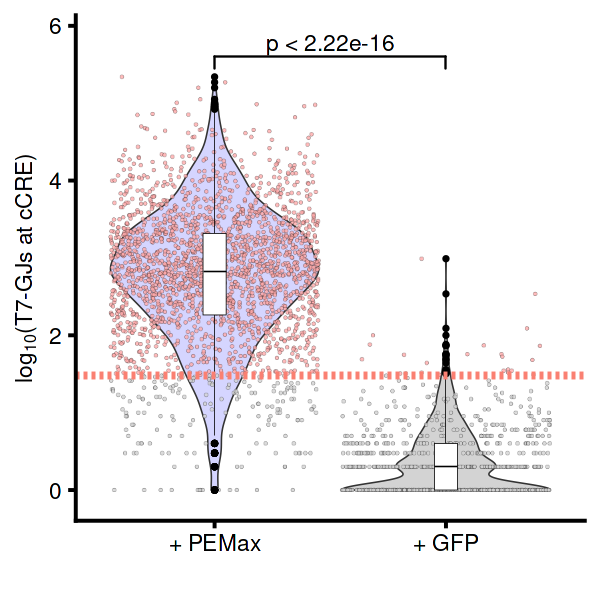

In [14]:
r.df <- rbind(r1_t7_processed[r1_t7_processed$overlapping_CRE != "",],
               r2_t7_processed[r2_t7_processed$overlapping_CRE != "",],
               r3_t7_processed[r3_t7_processed$overlapping_CRE != "",])


r.df <- aggregate(n_reads ~ overlapping_CRE, data = r.df[,c("n_reads","overlapping_CRE")], FUN = sum)
r.df$type = "+ PEMax"

n.df <- rbind(n1_t7_processed[n1_t7_processed$overlapping_CRE != "",],
               n2_t7_processed[n2_t7_processed$overlapping_CRE != "",],
               n3_t7_processed[n3_t7_processed$overlapping_CRE != "",])
           
n.df <- aggregate(n_reads ~ overlapping_CRE, data = n.df[,c("n_reads","overlapping_CRE")], FUN = sum)
n.df$type = "+ GFP"

plot_df <- rbind(r.df,n.df)

plot_df$hit <- ifelse(log10(plot_df$n_reads) > log10(30),"yes","no")


perc_reads <- 100*sum(plot_df[plot_df$type == "+ GFP",]$n_reads) / 
           sum(plot_df$n_reads) 

mean_FC <- mean(plot_df[plot_df$type == "+ PEMax",]$n_reads) / 
           mean(plot_df[plot_df$type == "+ GFP",]$n_reads)           
message(mean_FC)
plot_df$type <- factor(plot_df$type, levels = c("+ PEMax", "+ GFP"))
c <- ggplot(plot_df,aes(x=type,y=log10(n_reads),fill=type)) + 
  geom_violin(scale="width",linewidth=.2) + 
  geom_jitter_rast(data=plot_df[order(plot_df$hit),],aes(x=type,y=log10(n_reads),fill=hit),
              alpha=.8,color="black",shape=21,width=0.45,size=.5,stroke=.05) + 
  geom_boxplot(width=.1,fill="white",color="black",linewidth=.1, outlier.size = 0.3) +
#   stat_compare_means(method = "wilcox.test", label = "p.signif", 
#                      comparisons = list(c("+ pegRNA lib.\n+ PEMax", "+ pegRNA lib.\n- PEMax")), 
#                      size = 4) + 
  stat_compare_means(
      method = "wilcox.test",
      comparisons = list(c("+ PEMax", "+ GFP")),
      aes(label = paste0("p = ", after_stat(p.format))),
      size = 8/.pt,
      label.y = log10(max(plot_df$n_reads))*1.0)+
  scale_fill_manual(values = c(
                  "+ PEMax" = "#d5d5ff",
                  "+ GFP"   = "lightgrey",
                  "yes"     = "#ffaaaa",
                  "no"      = "lightgrey"
                )) +
  ylim(log10(min(plot_df$n_reads))-.1,log10(max(plot_df$n_reads))+.5) + 
#   annotate("text", x = 1.5, y = log10(max(plot_df$n_reads)) + .45,
#          label = paste0("+ GFP % of reads = ", signif(perc_reads,2), "%"), size = 3) +
  theme_classic() +
  theme(text = element_text(size = 8),
              axis.title = element_text(size = 8),
              axis.text = element_text(size = 8),
    axis.line = element_line(color = "black"),
    panel.grid = element_blank(),legend.position="none",
    axis.text.x = element_text()
    ) + 
  xlab("") +
  ylab(bquote(log[10]*.("(T7-GJs at cCRE)"))) + 
  geom_hline(yintercept=log10(30),linetype="dashed",color="salmon",linewidth=1)

options(repr.plot.width=3, repr.plot.height=3, repr.plot.res=200)
c

Printing out quantitative stats that are mentioned in the manuscript:

In [15]:
mean_pos <- mean(plot_df[plot_df$type == "+ PEMax", ]$n_reads)
sd_pos   <- sd(plot_df[plot_df$type == "+ PEMax", ]$n_reads)

mean_neg <- mean(plot_df[plot_df$type != "+ PEMax", ]$n_reads)
sd_neg   <- sd(plot_df[plot_df$type != "+ PEMax", ]$n_reads)

fold_change <- mean_pos / mean_neg

wilcox_res <- wilcox.test(
  plot_df[plot_df$type == "+ PEMax", ]$n_reads,
  plot_df[plot_df$type != "+ PEMax", ]$n_reads
)

cat(
  "+PEMax mean reads per targeted cCRE: ", round(mean_pos, 1), "\n",
  "+PEMax SD: ", round(sd_pos, 1), "\n",
  "+GFP mean reads per targeted cCRE: ", round(mean_neg, 1), "\n",
  "+GFP SD: ", round(sd_neg, 1), "\n",
  "Fold-change (+PEMax / +GFP): ", round(fold_change, 1), "\n",
  "Wilcoxon rank-sum P-value: ", format(wilcox_res$p.value, scientific = TRUE, digits = 3), "\n",
  sep = ""
)

wilcox_res

median_pos <- median(plot_df[plot_df$type == "+ PEMax", ]$n_reads)
iqr_pos     <- IQR(plot_df[plot_df$type == "+ PEMax", ]$n_reads)
q_pos       <- quantile(plot_df[plot_df$type == "+ PEMax", ]$n_reads, c(0.25, 0.75))
median_neg <- median(plot_df[plot_df$type != "+ PEMax", ]$n_reads)
iqr_neg     <- IQR(plot_df[plot_df$type != "+ PEMax", ]$n_reads)
q_neg       <- quantile(plot_df[plot_df$type != "+ PEMax", ]$n_reads, c(0.25, 0.75))
median_fold_change <- median_pos / median_neg
cat(
  "+PEMax median reads: ", round(median_pos, 1), " (IQR: ", round(q_pos[1],1), "-", round(q_pos[2],1), ")\n",
  "+GFP median reads: ", round(median_neg, 1), " (IQR: ", round(q_neg[1],1), "-", round(q_neg[2],1), ")\n",
  "Fold-change (median +PEMax / +GFP): ", round(median_fold_change, 1), "\n",
  sep = ""
)

+PEMax mean reads per targeted cCRE: 3174.1
+PEMax SD: 10935.6
+GFP mean reads per targeted cCRE: 6
+GFP SD: 36.3
Fold-change (+PEMax / +GFP): 528.1
Wilcoxon rank-sum P-value: 0e+00



	Wilcoxon rank sum test with continuity correction

data:  plot_df[plot_df$type == "+ PEMax", ]$n_reads and plot_df[plot_df$type != "+ PEMax", ]$n_reads
W = 1898314, p-value < 2.2e-16
alternative hypothesis: true location shift is not equal to 0


+PEMax median reads: 670.5 (IQR: 183.2-2069.8)
+GFP median reads: 2 (IQR: 1-4)
Fold-change (median +PEMax / +GFP): 335.2


## Figure 2D
Correlation between technical replicates within and across cell lines (i.e. K562 and HEK293T)

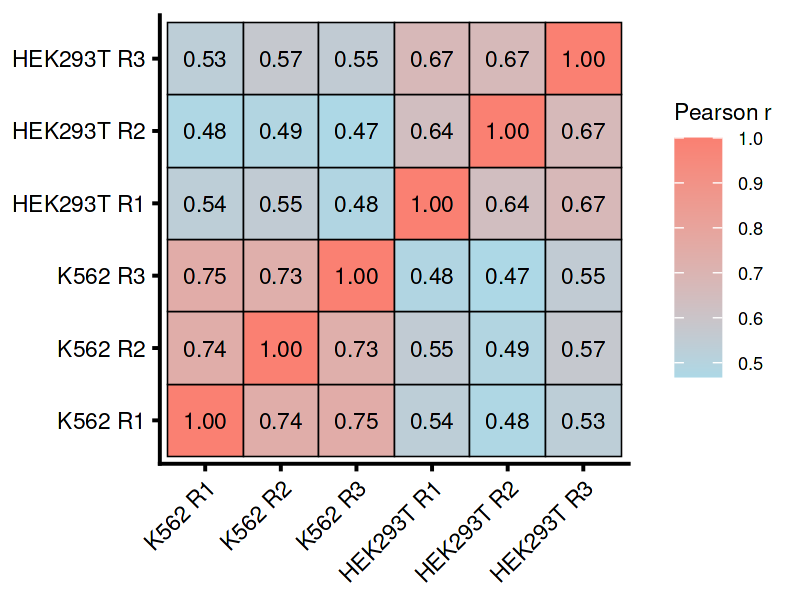

In [16]:
# Load required libraries
library(ggplot2)
library(reshape2)

# 1) Prepare a named list of your six data frames
# Each df must have 'location' and 'n_umis' columns
dfs <- list(
  "K562 R1"     = r1_t7_processed,
  "K562 R2"     = r2_t7_processed,
  "K562 R3"     = r3_t7_processed,
  "HEK293T R1"  = r1_t7_processed_hek,
  "HEK293T R2"  = r2_t7_processed_hek,
  "HEK293T R3"  = r3_t7_processed_hek
)

# 2) Define a helper to filter and aggregate by location for n_umis
agg_umis <- function(df) {
  # Filter: non-NA location & n_umis ≥ 10
  df2 <- df[!is.na(df$location) & df$n_reads > 30 & df$n_umis > 10, c("location", "n_reads")]
  # Sum n_umis per location
  aggregate(n_reads ~ location, data = df2, sum)
}

# 3) Apply aggregation to each sample
daggs <- lapply(dfs, agg_umis)

# 4) Initialize correlation matrix
sample_names <- names(daggs)
n <- length(sample_names)
corr_mat <- matrix(NA, nrow = n, ncol = n,
                   dimnames = list(sample_names, sample_names))

# 5) Compute pairwise Pearson correlations
for (i in seq_len(n)) {
  for (j in seq_len(n)) {
    df1 <- daggs[[i]]
    df2 <- daggs[[j]]
    # Full outer join on location
    merged <- merge(df1, df2, by = "location", all = TRUE,
                    suffixes = c(".x", ".y"))
    # Replace NA with 0
    merged$n_reads.x[is.na(merged$n_reads.x)] <- 0
    merged$n_reads.y[is.na(merged$n_reads.y)] <- 0
    # Filter for locations with ≥10 UMIs in both samples
    sel <- merged$n_reads.x >= 10 & merged$n_reads.y >= 10
    x <- log10(merged$n_reads.x[sel])
    y <- log10(merged$n_reads.y[sel])
    # Compute Pearson
    corr_mat[i, j] <- cor(x, y, method = "pearson")
  }
}

# 6) Melt and plot heatmap
corr_long <- melt(corr_mat, varnames = c("Sample1", "Sample2"),
                  value.name = "PearsonR")


d <- ggplot(corr_long, aes(x = Sample1, y = Sample2, fill = PearsonR)) +
  geom_tile(color = "black") +
  geom_text(aes(label = sprintf("%.2f", PearsonR)), size = 8/.pt) +
  scale_fill_gradient(low = "lightblue", high = "salmon", name = "Pearson r")  +
  theme_classic() +
  theme(text = element_text(size = 8),
              axis.text = element_text(size = 8),
    axis.text.x = element_text(angle = 45, hjust = 1),
    axis.title = element_blank(),
    panel.grid = element_blank()
  )

options(repr.plot.width = 4, repr.plot.height = 3, repr.plot.res = 200)
d

In [17]:
# Load required libraries
library(ggplot2)
library(reshape2)

# 1) Prepare a named list of your six data frames
dfs <- list(
  "K562 R1"     = r1_t7_processed,
  "K562 R2"     = r2_t7_processed,
  "K562 R3"     = r3_t7_processed,
  "HEK293T R1"  = r1_t7_processed_hek,
  "HEK293T R2"  = r2_t7_processed_hek,
  "HEK293T R3"  = r3_t7_processed_hek
)

# 2) Aggregate by location, keeping both n_reads and n_umis
agg_counts <- function(df) {
  df2 <- df[!is.na(df$location) & df$location != "", c("location", "n_reads", "n_umis")]
  aggregate(cbind(n_reads, n_umis) ~ location, data = df2, sum)
}

daggs <- lapply(dfs, agg_counts)

# 3) Compute pairwise Pearson correlations and overlapping site counts
sample_names <- names(daggs)
n <- length(sample_names)

corr_mat <- matrix(NA, nrow = n, ncol = n,
                   dimnames = list(sample_names, sample_names))
nsite_mat <- matrix(NA, nrow = n, ncol = n,
                    dimnames = list(sample_names, sample_names))

pair_stats <- data.frame()

for (i in seq_len(n)) {
  for (j in seq_len(n)) {
    df1 <- daggs[[i]]
    df2 <- daggs[[j]]

    merged <- merge(df1, df2, by = "location", all = TRUE,
                    suffixes = c(".x", ".y"))

    merged$n_reads.x[is.na(merged$n_reads.x)] <- 0
    merged$n_reads.y[is.na(merged$n_reads.y)] <- 0
    merged$n_umis.x[is.na(merged$n_umis.x)] <- 0
    merged$n_umis.y[is.na(merged$n_umis.y)] <- 0

    # Match manuscript threshold:
    # >30 raw reads and >10 deduplicated reads in both replicates
    sel <- merged$n_reads.x > 30 & merged$n_reads.y > 30 &
           merged$n_umis.x > 10 & merged$n_umis.y > 10

    n_sites <- sum(sel)

    if (n_sites >= 2) {
      x <- log10(merged$n_reads.x[sel])
      y <- log10(merged$n_reads.y[sel])
      r <- cor(x, y, method = "pearson")
    } else {
      r <- NA
    }

    corr_mat[i, j] <- r
    nsite_mat[i, j] <- n_sites

    pair_stats <- rbind(pair_stats, data.frame(
      Sample1 = sample_names[i],
      Sample2 = sample_names[j],
      PearsonR = r,
      n_sites = n_sites,
      stringsAsFactors = FALSE
    ))
  }
}

# 4) Keep only unique pairwise comparisons (upper triangle, excluding diagonal)
pair_stats_unique <- pair_stats[match(
  apply(combn(sample_names, 2), 2, paste, collapse = "___"),
  apply(pair_stats[, c("Sample1", "Sample2")], 1, function(x) paste(sort(x), collapse = "___"))
), ]

# Alternative safer way:
pair_stats_unique <- do.call(rbind, lapply(seq_len(n - 1), function(i) {
  do.call(rbind, lapply((i + 1):n, function(j) {
    subset(pair_stats, Sample1 == sample_names[i] & Sample2 == sample_names[j])
  }))
}))

# 5) K562 biological replicate comparisons only
k562_pairs <- subset(pair_stats_unique,
                     grepl("^K562", Sample1) & grepl("^K562", Sample2))

cat("K562 biological replicate comparisons:\n")
print(k562_pairs)

cat("\nK562 Pearson R range:",
    sprintf("%.2f", min(k562_pairs$PearsonR, na.rm = TRUE)),
    "to",
    sprintf("%.2f", max(k562_pairs$PearsonR, na.rm = TRUE)), "\n")

cat("K562 overlapping junction range:",
    min(k562_pairs$n_sites, na.rm = TRUE),
    "to",
    max(k562_pairs$n_sites, na.rm = TRUE), "\n\n")

# 6) HEK293T biological replicate comparisons only
hek_pairs <- subset(pair_stats_unique,
                    grepl("^HEK293T", Sample1) & grepl("^HEK293T", Sample2))

cat("HEK293T biological replicate comparisons:\n")
print(hek_pairs)

cat("\nHEK293T Pearson R range:",
    sprintf("%.2f", min(hek_pairs$PearsonR, na.rm = TRUE)),
    "to",
    sprintf("%.2f", max(hek_pairs$PearsonR, na.rm = TRUE)), "\n")

cat("HEK293T overlapping junction range:",
    min(hek_pairs$n_sites, na.rm = TRUE),
    "to",
    max(hek_pairs$n_sites, na.rm = TRUE), "\n\n")

# 7) K562 vs HEK293T matched / cross-cell-type comparisons
cross_pairs <- subset(pair_stats_unique,
                      (grepl("^K562", Sample1) & grepl("^HEK293T", Sample2)) |
                      (grepl("^HEK293T", Sample1) & grepl("^K562", Sample2)))

cat("K562 vs HEK293T comparisons:\n")
print(cross_pairs)

cat("\nK562 vs HEK293T Pearson R range:",
    sprintf("%.2f", min(cross_pairs$PearsonR, na.rm = TRUE)),
    "to",
    sprintf("%.2f", max(cross_pairs$PearsonR, na.rm = TRUE)), "\n")

cat("K562 vs HEK293T overlapping junction range:",
    min(cross_pairs$n_sites, na.rm = TRUE),
    "to",
    max(cross_pairs$n_sites, na.rm = TRUE), "\n")

K562 biological replicate comparisons:
  Sample1 Sample2  PearsonR n_sites
2 K562 R1 K562 R2 0.7412181     582
3 K562 R1 K562 R3 0.7467313     578
9 K562 R2 K562 R3 0.7303164     566

K562 Pearson R range: 0.73 to 0.75 
K562 overlapping junction range: 566 to 582 

HEK293T biological replicate comparisons:
      Sample1    Sample2  PearsonR n_sites
23 HEK293T R1 HEK293T R2 0.6376839     138
24 HEK293T R1 HEK293T R3 0.6746133     154
30 HEK293T R2 HEK293T R3 0.6686057     187

HEK293T Pearson R range: 0.64 to 0.67 
HEK293T overlapping junction range: 138 to 187 

K562 vs HEK293T comparisons:
   Sample1    Sample2  PearsonR n_sites
4  K562 R1 HEK293T R1 0.5350627     219
5  K562 R1 HEK293T R2 0.4773722     293
6  K562 R1 HEK293T R3 0.5332280     287
10 K562 R2 HEK293T R1 0.5507742     215
11 K562 R2 HEK293T R2 0.4888573     277
12 K562 R2 HEK293T R3 0.5743816     268
16 K562 R3 HEK293T R1 0.4846407     215
17 K562 R3 HEK293T R2 0.4678870     275
18 K562 R3 HEK293T R3 0.5522105     259

K

## Figure 2E
Visualization of T7 reads across each human chromosome

# of unique T7SSs: 2115

# of unique cCREs: 1688



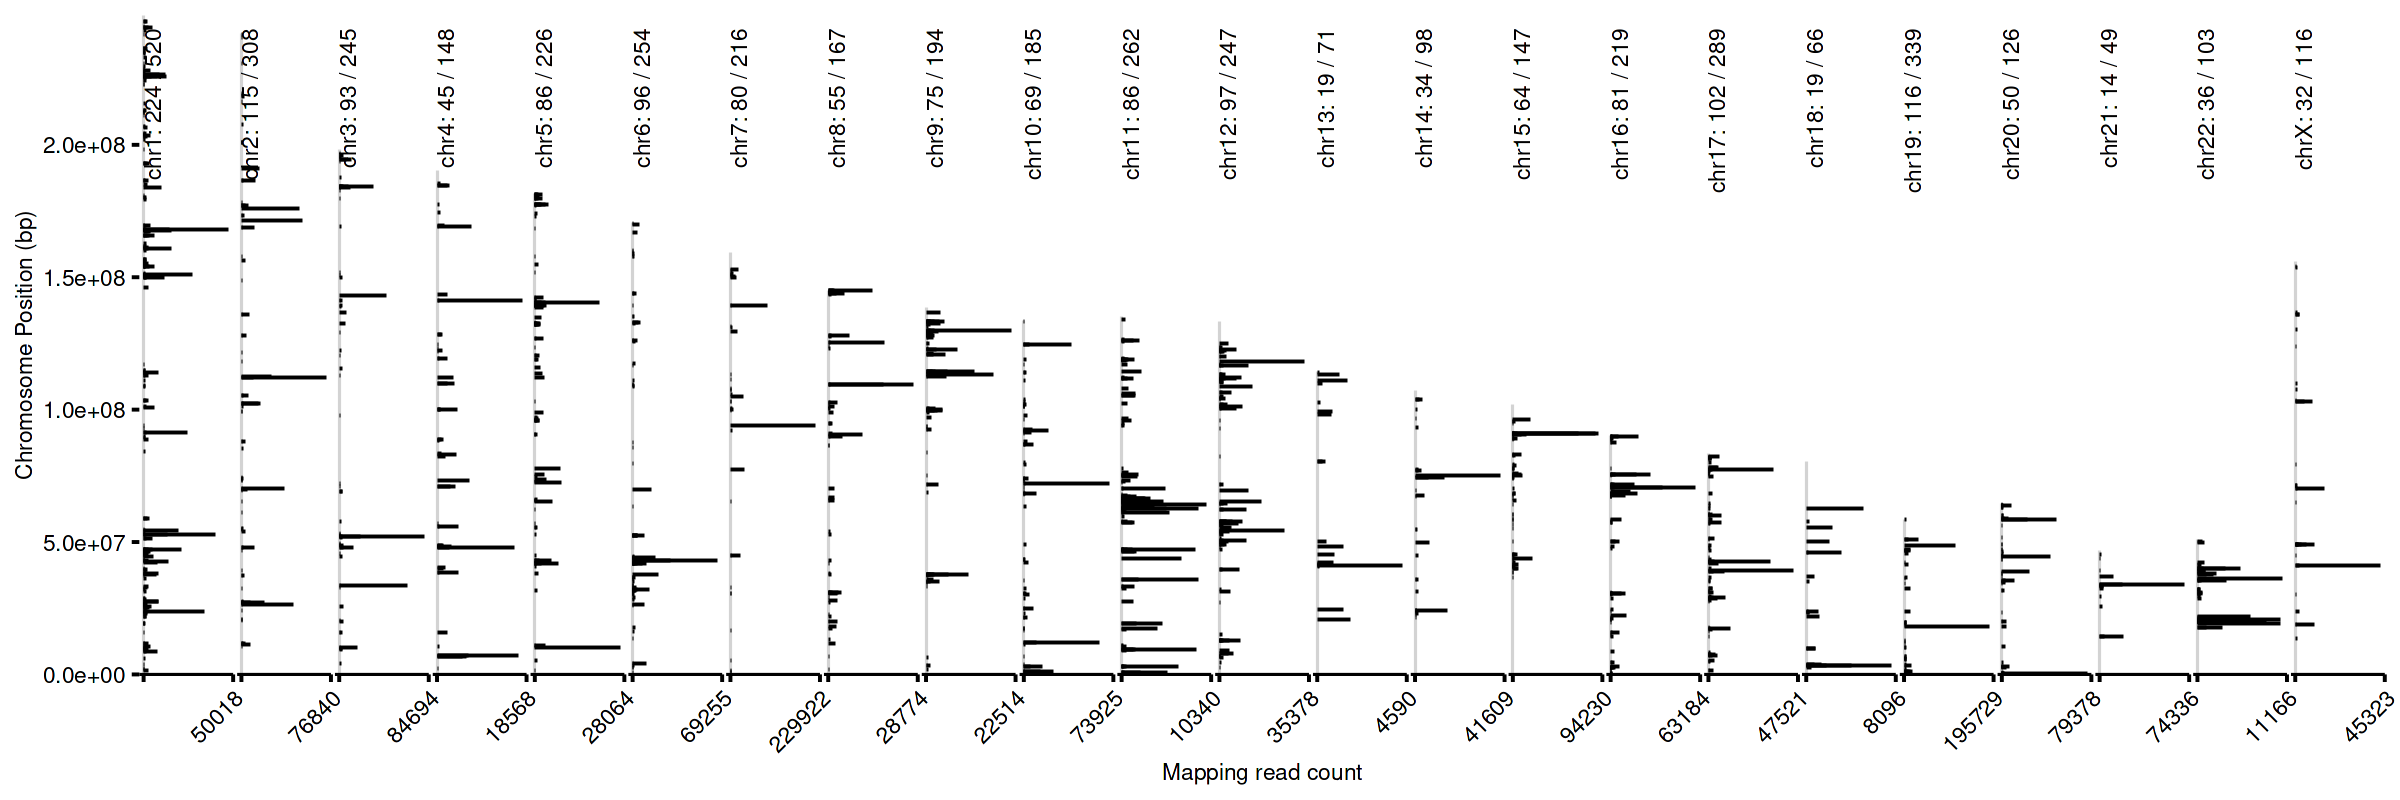

In [18]:
r.all <- rbind(r1_t7_processed[is.na(r1_t7_processed$overlapping_CRE) == FALSE,],
               r2_t7_processed[is.na(r2_t7_processed$overlapping_CRE) == FALSE,],
               r3_t7_processed[is.na(r3_t7_processed$overlapping_CRE) == FALSE,])


r.all <- aggregate(cbind(n_umis, n_reads) ~ overlapping_CRE+location,
                      data = r.all[,c("n_reads","n_umis","overlapping_CRE","location")],
                      FUN = sum)

r.all <- r.all[r.all$n_reads >= 30 & r.all$n_umis >= 10,]

message(paste0("# of unique T7SSs: ",length(unique(r.all$location))))
message(paste0("# of unique cCREs: ",length(unique(r.all$overlapping_CRE))))

chr.sizes <- read.csv("../t7_mapping/v1_18K_K562/hg38.chrom.standard.sizes", header = FALSE, sep="\t")
colnames(chr.sizes) <- c("chr","size")
chr.sizes <- chr.sizes[chr.sizes$chr != "chrY",]

r.all$chr <- sub("-.*", "", r.all$overlapping_CRE)

# 1) Extract numeric position from the 'location' column
r.all$pos <- as.numeric(sub("^[^-]+-", "", r.all$location))

chrom_order <- c(paste0("chr", 1:22), "chrX")
chrom_order <- intersect(chrom_order, unique(chr.sizes$chr))
r.all$chr     <- factor(r.all$chr,     levels = chrom_order)
chr.sizes$chr <- factor(chr.sizes$chr, levels = chrom_order)

chr_counts <- as.data.frame(table(r.all$chr), stringsAsFactors = FALSE)
names(chr_counts) <- c("chr","Freq")
chr_counts$label <- paste0(chr_counts$chr, ": ", chr_counts$Freq)
label_map <- setNames(chr_counts$label, chr_counts$chr)

# 3) Determine common x-axis limits (max chromosome size)
max_size <- max(chr.sizes$size)


# Horizontal version: one horizontal line per site, x = n_reads
f <- ggplot(r.all, aes(y = pos, xmin = 0, xmax = n_reads)) +

   #geom_vline(xintercept = 0, color = "black") +
    geom_segment(
      data = chr.sizes,
      aes(x = 0, xend = 0, y = 0, yend = size),
      inherit.aes = FALSE,
      color = "lightgrey",linewidth=.4
    ) +
  geom_linerange(orientation = "y") +
  facet_wrap(~ chr, nrow = 1, strip.position = "top", scales = "free_x") +
  scale_y_continuous(
    limits = c(0, max_size),
    expand = expansion(add = c(0, 0)),
    name = "Chromosome Position (bp)"
  ) +
  scale_x_continuous(
    breaks = function(lims) c(0, lims[2]),
    labels = function(x) ifelse(x == 0, "", format(x, scientific = FALSE, digits = 2, trim = TRUE))
  ) +
  labs(x = "Mapping read count") +
  theme_classic() +
  theme(text = element_text(size = 8),
              axis.title = element_text(size = 8),
              axis.text = element_text(size = 8),
    # remove facet strips entirely (old annotation)
    strip.text = element_blank(),
    strip.background = element_blank(),

    axis.text.x = element_text(angle = 45, hjust = 1),
    axis.line = element_blank(),
    axis.line.x.bottom = element_line(color = "black", linewidth = 0.4),
    #axis.line.y.left   = element_line(color = "black"),
    axis.line.y.left = element_blank(),
    panel.grid = element_blank(),
    legend.position = "none",
    panel.spacing = unit(0.1, "lines")
  )

chr_counts <- as.data.frame(table(unique(r.all[,c("overlapping_CRE","chr")])$chr))
colnames(chr_counts) <- c("chr","Freq")
chr_designed <- unique(oligos[is.na(oligos$CRE_chr) == FALSE,c("CRE","CRE_chr")])
chr_designed <- as.data.frame(table(chr_designed$CRE_chr))
colnames(chr_designed) <- c("chr","Freq")
chr_counts$Freq_program <- chr_designed$Freq[match(chr_counts$chr,chr_designed$chr)]

chr_counts$label <- paste0(chr_counts$chr, ": ", chr_counts$Freq, " / ",chr_counts$Freq_program)

chr_counts$x <- 0
chr_counts$y <- max_size * 0.98
f <- f +
  geom_text(
    data = chr_counts,
    aes(x = x, y = y, label = label),
    inherit.aes = FALSE,
    angle = 90,
    hjust = 1,
    vjust = 1,
    size = 8/.pt
  )

options(repr.plot.width = 12, repr.plot.height = 4, repr.plot.res = 200)
f 

In [19]:
length(unique(r.all[r.all$n_reads >= 30 & r.all$n_umis >= 10,]$overlapping_CRE))

[1] 1688

## Figure 2F
### Prioritizing top 100 CREs to follow up on in a secondary screen (smaller pool)
Let's get a list of CREs that are detected in all three replicates. There could be multiple T7 read start positions (rows in the dataframe) that overlap the same CRE since we designed 4 constructs per targetted CRE. We need to collpase these so that if there are 4 different T7 read start locations overlapping a given CRE, the UMI's are summed across those different possible start positions for that CRE such that we have a single UMI count for any given CRE. Then we can get a list of CREs that had at least 20 UMIs for all replicates.

In [20]:
aggregate_CRE <- function(rep_df, rep_id) {
    # Keep both umi + read counts
    rep <- rep_df[!is.na(rep_df$overlapping_CRE),
                  c("n_umis", "n_reads", "CRE")]
    # Sum both columns by CRE
    rep <- aggregate(cbind(n_umis, n_reads) ~ CRE,
                     data = rep,
                     FUN = sum)
    # Add replicate label
    rep$type <- rep_id
    rep
}


# Collapse CRE T7 UMI counts for replicate 1
rep1 <- aggregate_CRE(r1_t7_processed,"R1")

# Collapse CRE T7 UMI counts for replicate 2
rep2 <- aggregate_CRE(r2_t7_processed,"R2")

# Collapse CRE T7 UMI counts for replicate 3
rep3 <- aggregate_CRE(r3_t7_processed,"R3")

# Subset to CREs with at least 20 UMIs
rep1 <- rep1[rep1$n_umis > 20,,drop=FALSE]
rep2 <- rep2[rep2$n_umis > 20,,drop=FALSE]
rep3 <- rep3[rep3$n_umis > 20,,drop=FALSE]

# Get a list of CREs that were detected in all 3 replicates
consistent_CREs <- intersect(intersect(rep1$CRE,
                                       rep2$CRE),
                                       rep3$CRE)

length(consistent_CREs)

[1] 330

Subsetting each replicate to only include CREs that were detected across all 3 replicates:

In [21]:
rep1 <- rep1[rep1$CRE %in% consistent_CREs,]
rep2 <- rep2[rep2$CRE %in% consistent_CREs,]
rep3 <- rep3[rep3$CRE %in% consistent_CREs,]

Summing the T7 count values for each CRE across all three replicates

In [22]:
all_reps <- rbind(rep1, rep2, rep3)
all_reps <- aggregate(cbind(n_umis, n_reads) ~ CRE,
                      data = all_reps,
                      FUN = sum)

Adding the relative abundance of each CRE in the plasmid library:

In [23]:
all_reps$CRE_ratio <- CRE_counts$ratio[match(all_reps$CRE,CRE_counts$CRE)]

Definining an "edit ratio" as the relative abundance of T7 transcripts overlapping a CRE divided by the relative abundance of the pegRNAs targetting that CRE in the plasmid library:

In [24]:
all_reps$edit_ratio <- (all_reps$n_umis / sum(all_reps$n_umis)) / (all_reps$CRE_ratio)
all_reps <- all_reps[order(-all_reps$edit_ratio),]
all_reps$rank <- 1:nrow(all_reps)

In [25]:
top100 <- head(all_reps[order(-all_reps$edit_ratio),],100)$CRE

head(top100)

[1] "EH38D5692372" "EH38D5521053" "EH38D5850889" "EH38D5977845" "EH38D2738340"
[6] "EH38D4896988"

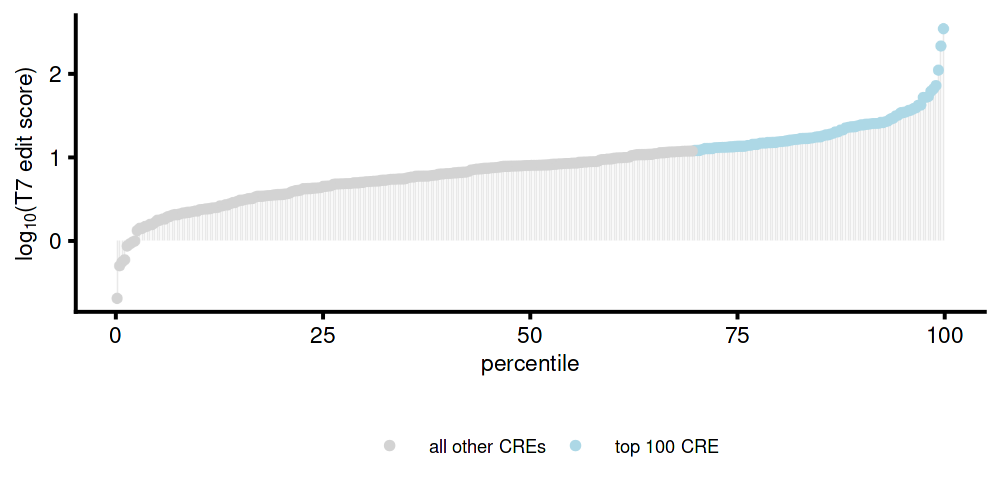

In [26]:
# 1) Sort your data frame by descending edit_ratio
all_reps <- all_reps[order(-all_reps$edit_ratio), ]

# 2) Reset CRE as a factor in that order
all_reps$CRE <- factor(all_reps$CRE, levels = all_reps$CRE)

all_reps$type <- ifelse(all_reps$CRE %in% top100,"top 100 CRE","all other CREs")

# 1) Compute percentiles (0–100) for edit_ratio
n      <- nrow(all_reps)
ranks  <- rank(all_reps$edit_ratio, ties.method = "average")
all_reps$percentile <- (ranks - 0.5) / n * 100



# 2) Plot percentile vs log10(edit_ratio) with stems
e <- ggplot(all_reps, aes(x = percentile, y = log10(edit_ratio),color=type)) +
  geom_segment(aes(x = percentile, xend = percentile,
                   y = 0,         yend = log10(edit_ratio)),
               color = "lightgrey",alpha=.5,linewidth=.2) +
  geom_point_rast(size = 1) +
  labs(color="") +
  scale_color_manual(values=c("lightgrey","lightblue")) +
  ylab(bquote(log[10]*.(paste0("(T7 edit score)")))) + 
        theme_classic() +
        theme(text = element_text(size = 8),
              axis.title = element_text(size = 8),
              axis.text = element_text(size = 8),
              axis.line = element_line(color = "black"),
              panel.grid = element_blank(),legend.position="bottom",
              axis.text.x = element_text()
            ) 

options(repr.plot.width = 5, repr.plot.height = 2.5, repr.plot.res = 200)
e

## Assembling and exporting final figure

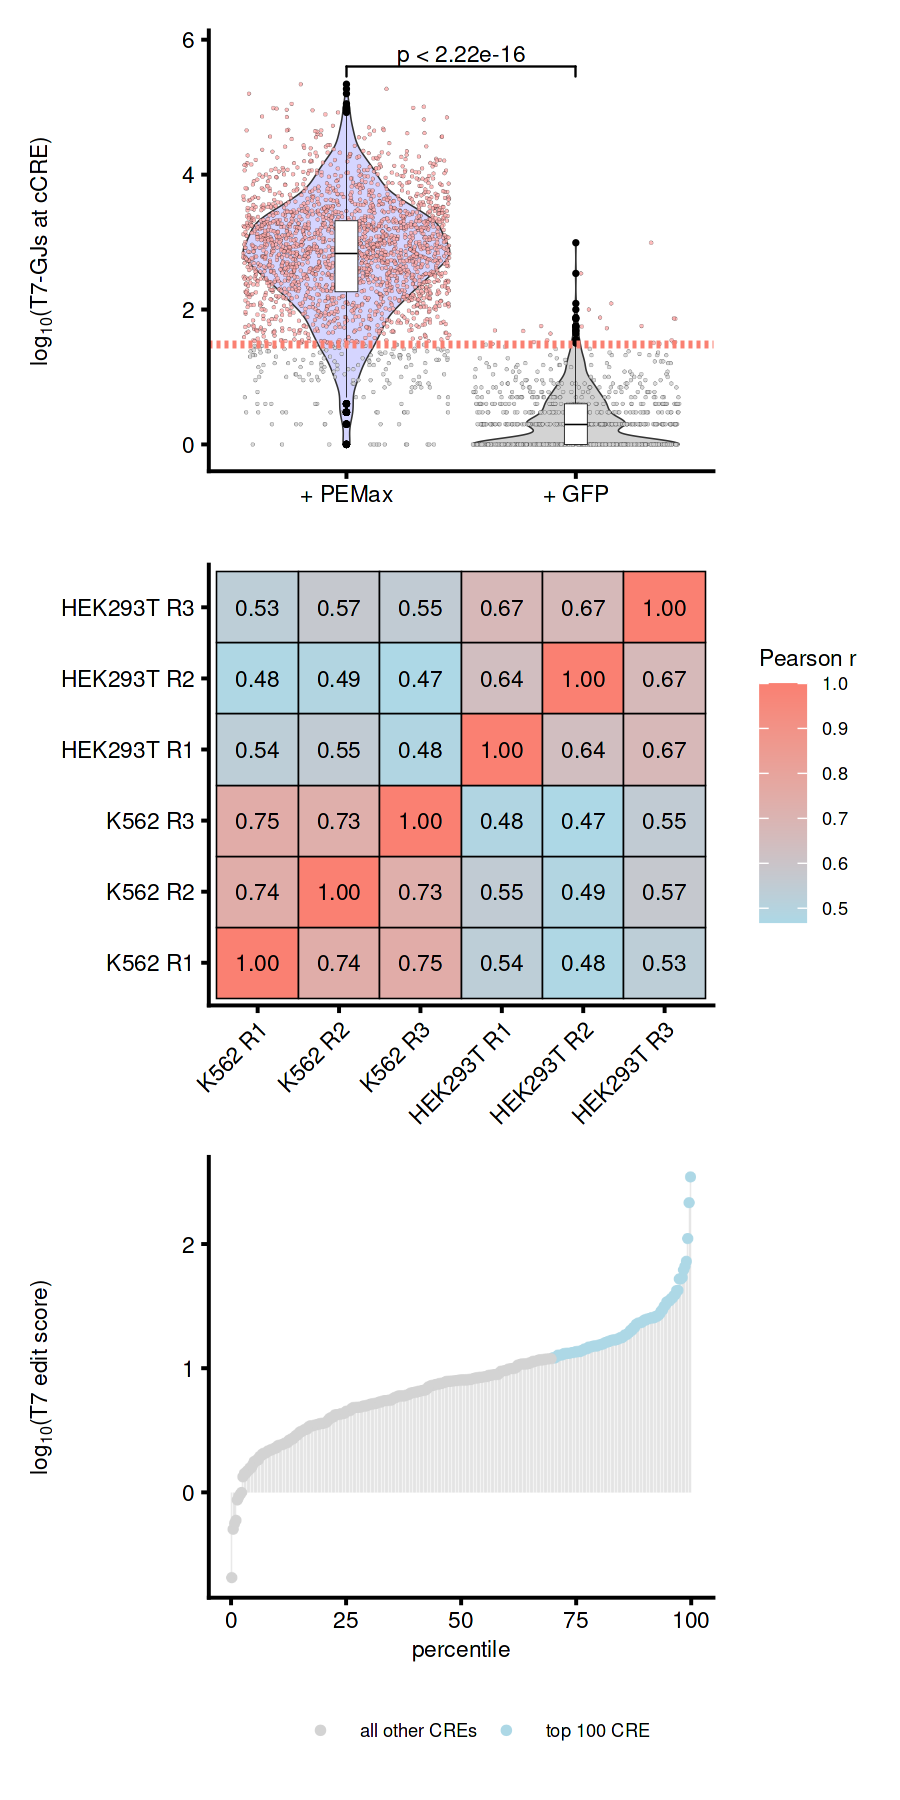

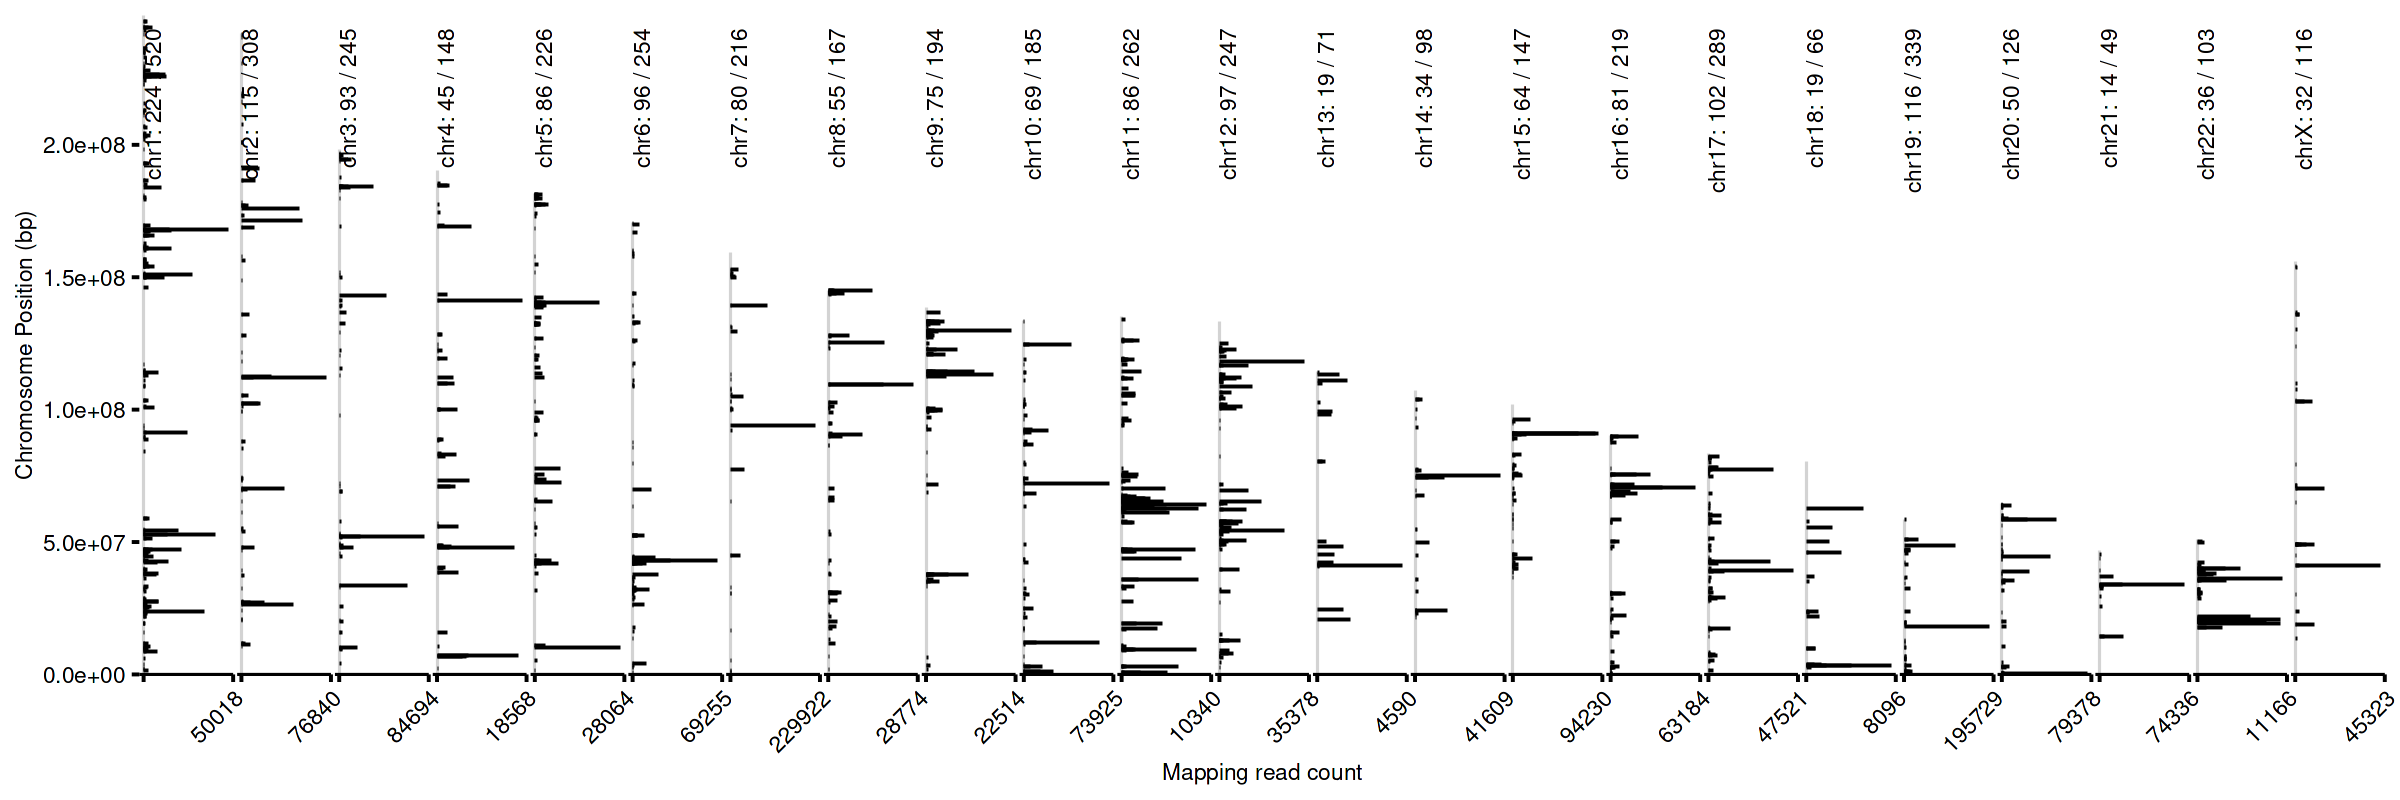

In [27]:
layout <- "
A
B
C
"

fig.c_e <- c + d + e +
  plot_layout(design = layout)

options(repr.plot.width = 4.5, repr.plot.height = 9, repr.plot.res = 200)
fig.c_e

options(repr.plot.width = 12, repr.plot.height = 4, repr.plot.res = 200)
f

In [28]:
ggsave('../figures/Figure2C-E.pdf', plot = fig.c_e, width = 92, height = 176, useDingbats = F, units = 'mm', device = 'pdf')

In [29]:
ggsave('../figures/Figure2F.pdf',plot = f, width = 149,height=47, useDingbats = F, units = 'mm', device = 'pdf')

## Supplementary Figure 2
### Sequencing read QC and statistics
The following summary dataframe was generated from *../19K-intronic_K562-3N-3d-T7/count_read_statistics.ipynb* to count the total number of raw fastq reads per sample, the fraction of reads containing the PCR primer site used for mapping, as well as the fraction of reads containing a pegRNA-specific sequence (TTGACGCGGT, in the evoPreQ1) and which should be plasmid-derived and not derived from editing events. Reading in that sumary dataframe:

In [28]:
summary_df <- read.delim("../../19K-intronic_K562-3N-3d-T7/t7_counts/summary_statistics.tsv", header = TRUE)

summary_df$sample_type <- ifelse(grepl("_R",summary_df$sample) == TRUE, "+ pegRNA lib.\n+ PEMax",
                          ifelse(grepl("_N",summary_df$sample) == TRUE, "+ pegRNA lib.\n- PEMax",
                                ""))

summary_df$replicate <- ifelse(grepl("R1",summary_df$sample) == TRUE | 
                               grepl("N1",summary_df$sample) == TRUE, "R1",
                        ifelse(grepl("R2",summary_df$sample) == TRUE | 
                               grepl("N2",summary_df$sample) == TRUE, "R2",      
                        ifelse(grepl("R3",summary_df$sample) == TRUE | 
                               grepl("N3",summary_df$sample) == TRUE, "R3", "")))

summary_df$perc_plasmid <- 100*summary_df$frac_plasmid
summary_df$perc_passing_filter <- 100*summary_df$frac_passing_filter
head(summary_df)

,sample,total_reads,n_reads_PCRF,n_reads_plasmid,frac_PCRF,frac_plasmid,n_reads_passing_filter,frac_passing_filter,sample_type,replicate,perc_plasmid,perc_passing_filter
,<chr>,<int>,<int>,<int>,<dbl>,<dbl>,<int>,<dbl>,<chr>,<chr>,<dbl>,<dbl>
1,t7_R1_S1,27558824,25371063,17560198,0.9206149,0.6371897,3550782,0.128843742,+ pegRNA lib. + PEMax,R1,63.71897,12.8843742
2,t7_R2_S2,27073971,24935101,16008430,0.9209990,0.5912849,4357723,0.160956182,+ pegRNA lib. + PEMax,R2,59.12849,16.0956182
3,t7_R3_S3,19475546,18113416,12336809,0.9300595,0.6334513,2752123,0.141311725,+ pegRNA lib. + PEMax,R3,63.34513,14.1311725
4,t7_N1_S4,25050052,23074634,21300851,0.9211412,0.8503316,63391,0.002530574,+ pegRNA lib. - PEMax,R1,85.03316,0.2530574
5,t7_N2_S5,21594849,19961227,18428962,0.9243513,0.8533962,89644,0.004151175,+ pegRNA lib. - PEMax,R2,85.33962,0.4151175
6,t7_N3_S6,20576939,18956086,17481356,0.9212296,0.8495606,73020,0.003548633,+ pegRNA lib. - PEMax,R3,84.95606,0.3548633


Getting statistics from the processed data above that indicate how many reads overlapped targeted cCREs:

In [29]:
sample_summary <- function(raw_df, processed_df, sample_name, condition) {
  data.frame(
    sample = sample_name,
    condition = condition,
    mapped_GJ_reads = sum(raw_df$n_reads),
    mapped_GJ_umis  = sum(raw_df$n_umis),
    cCRE_GJ_reads   = sum(processed_df[processed_df$overlapping_CRE != "",]$n_reads),
    cCRE_GJ_umis    = sum(processed_df[processed_df$overlapping_CRE != "",]$n_umis),
    frac_reads_to_cCRE = sum(processed_df[processed_df$overlapping_CRE != "",]$n_reads) / sum(raw_df$n_reads),
    frac_umis_to_cCRE  = sum(processed_df[processed_df$overlapping_CRE != "",]$n_umis) / sum(raw_df$n_umis)
  )
}

sample_df <- rbind(
  sample_summary(r1_t7, r1_t7_processed, "R1", "+ pegRNA lib.\n+ PEMax"),
  sample_summary(r2_t7, r2_t7_processed, "R2", "+ pegRNA lib.\n+ PEMax"),
  sample_summary(r3_t7, r3_t7_processed, "R3", "+ pegRNA lib.\n+ PEMax"),
  sample_summary(n1_t7, n1_t7_processed, "R1", "+ pegRNA lib.\n- PEMax"),
  sample_summary(n2_t7, n2_t7_processed, "R2", "+ pegRNA lib.\n- PEMax"),
  sample_summary(n3_t7, n3_t7_processed, "R3", "+ pegRNA lib.\n- PEMax")
)

head(sample_df)

,sample,condition,mapped_GJ_reads,mapped_GJ_umis,cCRE_GJ_reads,cCRE_GJ_umis,frac_reads_to_cCRE,frac_umis_to_cCRE
,<chr>,<chr>,<int>,<int>,<int>,<int>,<dbl>,<dbl>
1,R1,+ pegRNA lib. + PEMax,3550782,118843,2328997,58711,0.65591101,0.4940215
2,R2,+ pegRNA lib. + PEMax,4357723,119799,2965300,60877,0.68047005,0.5081595
3,R3,+ pegRNA lib. + PEMax,2752123,109421,1783913,54513,0.64819523,0.4981950
4,R1,+ pegRNA lib. - PEMax,63391,7044,1850,1116,0.02918395,0.1584327
5,R2,+ pegRNA lib. - PEMax,89644,7418,1490,1028,0.01662130,0.1385818
6,R3,+ pegRNA lib. - PEMax,73020,6234,1853,884,0.02537661,0.1418030


Adding to the other summary df:

In [30]:
summary_df$cCRE_GJ_reads <- sample_df$cCRE_GJ_reads[match(summary_df$n_reads_passing_filter,sample_df$mapped_GJ_reads)]
summary_df$perc_cCRE <- 100*summary_df$cCRE_GJ_reads / summary_df$n_reads_passing_filter
summary_df

sample,total_reads,n_reads_PCRF,n_reads_plasmid,frac_PCRF,frac_plasmid,n_reads_passing_filter,frac_passing_filter,sample_type,replicate,perc_plasmid,perc_passing_filter,cCRE_GJ_reads,perc_cCRE
<chr>,<int>,<int>,<int>,<dbl>,<dbl>,<int>,<dbl>,<chr>,<chr>,<dbl>,<dbl>,<int>,<dbl>
t7_R1_S1,27558824,25371063,17560198,0.9206149,0.6371897,3550782,0.128843742,+ pegRNA lib. + PEMax,R1,63.71897,12.8843742,2328997,65.591101
t7_R2_S2,27073971,24935101,16008430,0.9209990,0.5912849,4357723,0.160956182,+ pegRNA lib. + PEMax,R2,59.12849,16.0956182,2965300,68.047005
t7_R3_S3,19475546,18113416,12336809,0.9300595,0.6334513,2752123,0.141311725,+ pegRNA lib. + PEMax,R3,63.34513,14.1311725,1783913,64.819523
t7_N1_S4,25050052,23074634,21300851,0.9211412,0.8503316,63391,0.002530574,+ pegRNA lib. - PEMax,R1,85.03316,0.2530574,1850,2.918395
t7_N2_S5,21594849,19961227,18428962,0.9243513,0.8533962,89644,0.004151175,+ pegRNA lib. - PEMax,R2,85.33962,0.4151175,1490,1.662130
t7_N3_S6,20576939,18956086,17481356,0.9212296,0.8495606,73020,0.003548633,+ pegRNA lib. - PEMax,R3,84.95606,0.3548633,1853,2.537661


Visualizing relevant statistics:

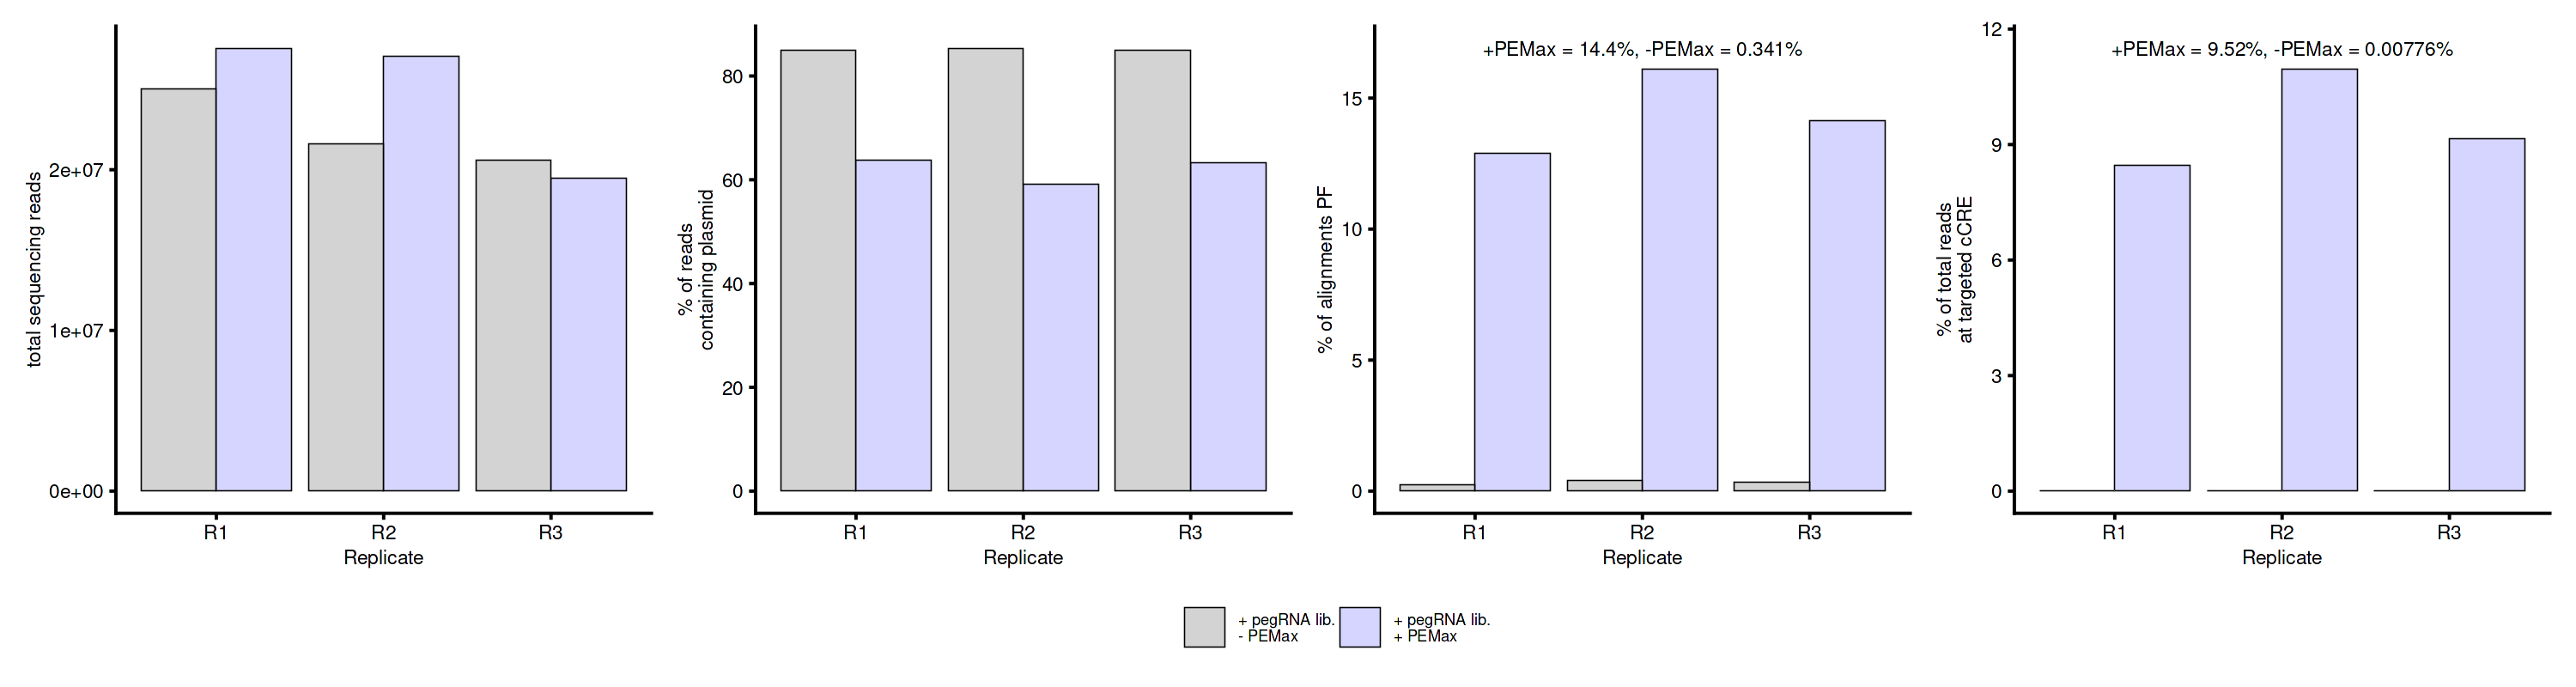

In [31]:
plot_summary_bar <- function(df, col_name) {
  
  ggplot(df, aes(x = replicate, y = .data[[col_name]], fill = sample_type)) +
    geom_bar(stat = "identity", position = "dodge",color="black",linewidth=.2) +
    theme_classic() +
    xlab("Replicate") +
    ylab(col_name) +
    scale_fill_manual(values = c("lightgrey", "#d5d5ff")) +
    theme(text = element_text(size = 8),
              axis.title = element_text(size = 8),
              axis.text = element_text(size = 8),
      axis.text.x = element_text(),
      legend.title = element_blank(),legend.position="bottom"
    )
}

a <- plot_summary_bar(summary_df, "total_reads") + ylab("total sequencing reads")
b <- plot_summary_bar(summary_df, "perc_plasmid") + ylab("% of reads\ncontaining plasmid")

mean_pass_R <- mean(summary_df[summary_df$sample_type == "+ pegRNA lib.\n+ PEMax","perc_passing_filter"])
mean_pass_N <- mean(summary_df[summary_df$sample_type == "+ pegRNA lib.\n- PEMax","perc_passing_filter"])
c <- plot_summary_bar(summary_df, "perc_passing_filter") + ylab("% of alignments PF")+
  annotate("text", x = 2, 
           y = max(summary_df$perc_passing_filter)*1.05,
           label = paste0("+PEMax = ", signif(mean_pass_R,3), "%, ",
                          "-PEMax = ", signif(mean_pass_N,3), "%"),
           size = 8/.pt)


summary_df$perc_total_cCRE <- 100 * summary_df$cCRE_GJ_reads / summary_df$total_reads
mean_total_cCRE_R <- mean(summary_df[summary_df$sample_type == "+ pegRNA lib.\n+ PEMax","perc_total_cCRE"])
mean_total_cCRE_N <- mean(summary_df[summary_df$sample_type == "+ pegRNA lib.\n- PEMax","perc_total_cCRE"])

d <- plot_summary_bar(summary_df, "perc_total_cCRE") + ylab("% of total reads\nat targeted cCRE")+
  annotate("text", x = 2, 
           y = max(summary_df$perc_total_cCRE)*1.05,
           label = paste0("+PEMax = ", signif(mean_total_cCRE_R,3), "%, ",
                          "-PEMax = ", signif(mean_total_cCRE_N,3), "%"),
           size = 8/.pt)

options(repr.plot.width = 15, repr.plot.height = 4, repr.plot.res = 200)
layout <- "
ABCD
"

supp_fig2 <- (a + b + c + d) +
  plot_layout(design = layout, guides = "collect") &
  theme(legend.position = "bottom")

supp_fig2

In [34]:
ggsave('../figures/SuppFig2.pdf', plot = supp_fig2, 
       width = 205, height = 65, useDingbats = F, units = 'mm', device = 'pdf')

In [32]:
## Means for fraction of all raw reads passing filtering
mean_pass_R <- mean(summary_df$perc_passing_filter[summary_df$sample_type == "+ pegRNA lib.\n+ PEMax"])
mean_pass_N <- mean(summary_df$perc_passing_filter[summary_df$sample_type == "+ pegRNA lib.\n- PEMax"])
fold_pass   <- mean_pass_R / mean_pass_N

cat("Mean % all reads passing filter, +PEMax:", mean_pass_R, "\n")
cat("Mean % all reads passing filter, +GFP:", mean_pass_N, "\n")
cat("Fold enrichment for passing filter (+PEMax / +GFP):", fold_pass, "\n\n")


## Means for fraction of T7-GJ reads overlapping targeted cCREs
## Use sample_df directly
sample_df$perc_cCRE <- 100 * sample_df$frac_reads_to_cCRE

mean_cCRE_R <- mean(sample_df$perc_cCRE[sample_df$condition == "+ pegRNA lib.\n+ PEMax"])
mean_cCRE_N <- mean(sample_df$perc_cCRE[sample_df$condition == "+ pegRNA lib.\n- PEMax"])
fold_cCRE   <- mean_cCRE_R / mean_cCRE_N

cat("Mean % T7-GJ reads overlapping targeted cCREs, +PEMax:", mean_cCRE_R, "\n")
cat("Mean % T7-GJ reads overlapping targeted cCREs, +GFP:", mean_cCRE_N, "\n")
cat("Fold enrichment for cCRE overlap among T7-GJs (+PEMax / +GFP):", fold_cCRE, "\n\n")




## Means for fraction of all raw reads passing filtering
mean_pass_R <- mean(summary_df$perc_total_cCRE[summary_df$sample_type == "+ pegRNA lib.\n+ PEMax"])
mean_pass_N <- mean(summary_df$perc_total_cCRE[summary_df$sample_type == "+ pegRNA lib.\n- PEMax"])
fold_pass   <- mean_pass_R / mean_pass_N

cat("Mean % all reads overlapping cCRE, +PEMax:", mean_pass_R, "\n")
cat("Mean % all reads overlapping cCRE, +GFP:", mean_pass_N, "\n")
cat("Fold enrichment for reads overlapping cCRE (+PEMax / +GFP):", fold_pass, "\n\n")


## Mean +/- SD reads per programmed T7-GJ used in Fig. 2C
r.tmp <- rbind(r1_t7_processed[r1_t7_processed$overlapping_CRE != "",],
               r2_t7_processed[r2_t7_processed$overlapping_CRE != "",],
               r3_t7_processed[r3_t7_processed$overlapping_CRE != "",])
r.tmp <- aggregate(n_reads ~ overlapping_CRE, data = r.tmp[,c("n_reads","overlapping_CRE")], FUN = sum)

n.tmp <- rbind(n1_t7_processed[n1_t7_processed$overlapping_CRE != "",],
               n2_t7_processed[n2_t7_processed$overlapping_CRE != "",],
               n3_t7_processed[n3_t7_processed$overlapping_CRE != "",])
n.tmp <- aggregate(n_reads ~ overlapping_CRE, data = n.tmp[,c("n_reads","overlapping_CRE")], FUN = sum)

mean_reads_R <- mean(r.tmp$n_reads)
sd_reads_R   <- sd(r.tmp$n_reads)

mean_reads_N <- mean(n.tmp$n_reads)
sd_reads_N   <- sd(n.tmp$n_reads)

fold_reads   <- mean_reads_R / mean_reads_N

cat("Mean reads per programmed T7-GJ, +PEMax:", mean_reads_R, "\n")
cat("SD reads per programmed T7-GJ, +PEMax:", sd_reads_R, "\n")
cat("Mean reads per programmed T7-GJ, +GFP:", mean_reads_N, "\n")
cat("SD reads per programmed T7-GJ, +GFP:", sd_reads_N, "\n")
cat("Fold difference in mean reads per programmed T7-GJ (+PEMax / +GFP):", fold_reads, "\n")

## Mean % of GFP-condition on-target T7-GJ reads, out of all T7-GJ reads across conditions
pct_GFP_of_all_T7GJ <- 100 * sum(sample_df[sample_df$condition == "+ pegRNA lib.\n- PEMax",]$cCRE_GJ_reads) /
    sum(sample_df$mapped_GJ_reads)

cat("GFP on-target T7-GJ reads, as % of all T7-GJ reads across conditions:", pct_GFP_of_all_T7GJ, "\n")
cat("Rounded (as reported in Fig. S2 legend):", signif(pct_GFP_of_all_T7GJ, 1), "%\n")

Mean % all reads passing filter, +PEMax: 14.37039 
Mean % all reads passing filter, +GFP: 0.3410127 
Fold enrichment for passing filter (+PEMax / +GFP): 42.14033 

Mean % T7-GJ reads overlapping targeted cCREs, +PEMax: 66.15254 
Mean % T7-GJ reads overlapping targeted cCREs, +GFP: 2.372729 
Fold enrichment for cCRE overlap among T7-GJs (+PEMax / +GFP): 27.88036 

Mean % all reads overlapping cCRE, +PEMax: 9.521116 
Mean % all reads overlapping cCRE, +GFP: 0.007763411 
Fold enrichment for reads overlapping cCRE (+PEMax / +GFP): 1226.409 

Mean reads per programmed T7-GJ, +PEMax: 3174.085 
SD reads per programmed T7-GJ, +PEMax: 10935.58 
Mean reads per programmed T7-GJ, +GFP: 6.010417 
SD reads per programmed T7-GJ, +GFP: 36.27427 
Fold difference in mean reads per programmed T7-GJ (+PEMax / +GFP): 528.0974 
GFP on-target T7-GJ reads, as % of all T7-GJ reads across conditions: 0.04770048 
Rounded (as reported in Fig. S2 legend): 0.05 %


## Supplementary Figure 3
### Correlation scatter plots between transfection replicates and detection rates of off target events
First, defining a function for correlation scatter plots:

In [33]:
compare_rep <- function(rep1, rep2, r1, r2,
                        min_reads_pre  = 30,
                        min_umis_pre   = 10,
                        min_reads_both = 10,
                        pseudo = 1) {

  # filter + aggregate reads by location
#   agg_reads <- function(df) {
#     df2 <- df[!is.na(df$location) & df$n_reads > min_reads_pre & df$n_umis > min_umis_pre,
#               c("location", "n_reads")]
#     aggregate(n_reads ~ location, data = df2, sum)
#   }

  agg_reads <- function(df) {
    df2 <- df[!is.na(df$location) &
              df$n_reads > min_reads_pre &
              df$n_umis > min_umis_pre,
              c("location", "n_reads")]
  
    aggregate(n_reads ~ location, data = df2, sum)
  }
    
    
  a1 <- agg_reads(rep1)
  a2 <- agg_reads(rep2)

  merged <- merge(a1, a2, by = "location", all = TRUE, suffixes = c(".r1", ".r2"))
  merged$n_reads.r1[is.na(merged$n_reads.r1)] <- 0
  merged$n_reads.r2[is.na(merged$n_reads.r2)] <- 0

  # correlation ONLY on locations detected in both
  sel_cor <- merged$n_reads.r1 >= min_reads_both & merged$n_reads.r2 >= min_reads_both
  pearson_corr  <- cor(log10(merged$n_reads.r1[sel_cor]),
                       log10(merged$n_reads.r2[sel_cor]), method = "pearson")
  spearman_corr <- cor(log10(merged$n_reads.r1[sel_cor]),
                       log10(merged$n_reads.r2[sel_cor]), method = "spearman")

  # plot ALL locations (including zeros) using pseudocount
  merged$det_class <- ifelse(merged$n_reads.r1 >= min_reads_both & merged$n_reads.r2 >= min_reads_both, "both","neither")

  message("both")
  message(nrow(merged[merged$det_class == "both",]))
    
  message("neither")
  message(nrow(merged[merged$det_class == "neither",]))
  ggplot(merged, aes(x = log10(n_reads.r1 + pseudo),
                     y = log10(n_reads.r2 + pseudo))) +
    # expand limits for annotation
    xlim(0,log10(max(merged$n_reads.r1))*1.2) +
    ylim(0,log10(max(merged$n_reads.r2))*1.2) +
    geom_point_rast(aes(fill=det_class), shape = 21, size = 2, alpha = 0.5,stroke=.1) +
    # optional: fit line only on "both"
    geom_smooth(data = merged[sel_cor, ],
                aes(x = log10(n_reads.r1 + pseudo),
                    y = log10(n_reads.r2 + pseudo)),
                method = "lm", inherit.aes = FALSE) +
    geom_hline(yintercept = log10(min_reads_both + pseudo), linetype = "dashed") +
    geom_vline(xintercept = log10(min_reads_both + pseudo), linetype = "dashed") +
    annotate("text", x = -Inf, y = Inf,
             label = paste0("Pearson (both): ", sprintf("%.3f", pearson_corr)),
             hjust = -0.05, vjust = 1.5, size = 4) +
    annotate("text", x = -Inf, y = Inf,
             label = paste0("Spearman (both): ", sprintf("%.3f", spearman_corr)),
             hjust = -0.05, vjust = 3.0, size = 4) +
    theme_classic() +
    theme(legend.position="none") +
    xlab(paste0("log10(", r1, " reads + ", pseudo, ")")) +
    ylab(paste0("log10(", r2, " reads + ", pseudo, ")")) +
    #ggtitle(paste0(r1, " vs ", r2)) +
    guides(fill = guide_legend(title = NULL)) + scale_fill_manual(values=c("lightblue","lightgrey"))
}

Next, generating CDF plots showing the fraction of observed T7 deletion junctions detected with varying read thresholds:

In [34]:
r1_t7_processed <- process_sample(r1_t7, CREs_gr, filter=FALSE)
r2_t7_processed <- process_sample(r2_t7, CREs_gr, filter=FALSE)
r3_t7_processed <- process_sample(r3_t7, CREs_gr, filter=FALSE)

r.all <- rbind(r1_t7_processed,
               r2_t7_processed,
               r3_t7_processed)


r.all <- aggregate(cbind(n_umis, n_reads) ~ location+overlapping_CRE,
                      data = r.all[,c("n_reads","n_umis","location","overlapping_CRE")],
                      FUN = sum)

r.all <- r.all[order(-r.all$n_reads),] 


n_total_on  <- nrow(r.all[r.all$overlapping_CRE != "",])
n_total_off <- nrow(r.all[r.all$overlapping_CRE == "",])


cdf_out <- data.frame()

for (threshold in 1:2000) {
    
    ## READS (n_reads)
    n_GJs <- nrow(r.all[r.all$n_reads >= threshold & r.all$overlapping_CRE != "",])
    cdf_out <- rbind(cdf_out, data.frame(threshold, 
                                         frac = n_GJs / n_total_on, 
                                         targeting = "TRUE",
                                         metric = "all reads"))
    
    n_GJs <- nrow(r.all[r.all$n_reads >= threshold & r.all$overlapping_CRE == "",])
    cdf_out <- rbind(cdf_out, data.frame(threshold, 
                                         frac = n_GJs / n_total_off, 
                                         targeting = "FALSE",
                                         metric = "all reads"))
    
    
    ## UMIs (n_umis)
    n_GJs <- nrow(r.all[r.all$n_umis >= threshold & r.all$overlapping_CRE != "",])
    cdf_out <- rbind(cdf_out, data.frame(threshold, 
                                         frac = n_GJs / n_total_on, 
                                         targeting = "TRUE",
                                         metric = "dedup. reads"))
    
    n_GJs <- nrow(r.all[r.all$n_umis >= threshold & r.all$overlapping_CRE == "",])
    cdf_out <- rbind(cdf_out, data.frame(threshold, 
                                         frac = n_GJs / n_total_off, 
                                         targeting = "FALSE",
                                         metric = "dedup. reads"))
}

# ensure numeric
cdf_out$threshold <- as.numeric(cdf_out$threshold)
cdf_out$frac <- as.numeric(cdf_out$frac)

Warning message:
“Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.”


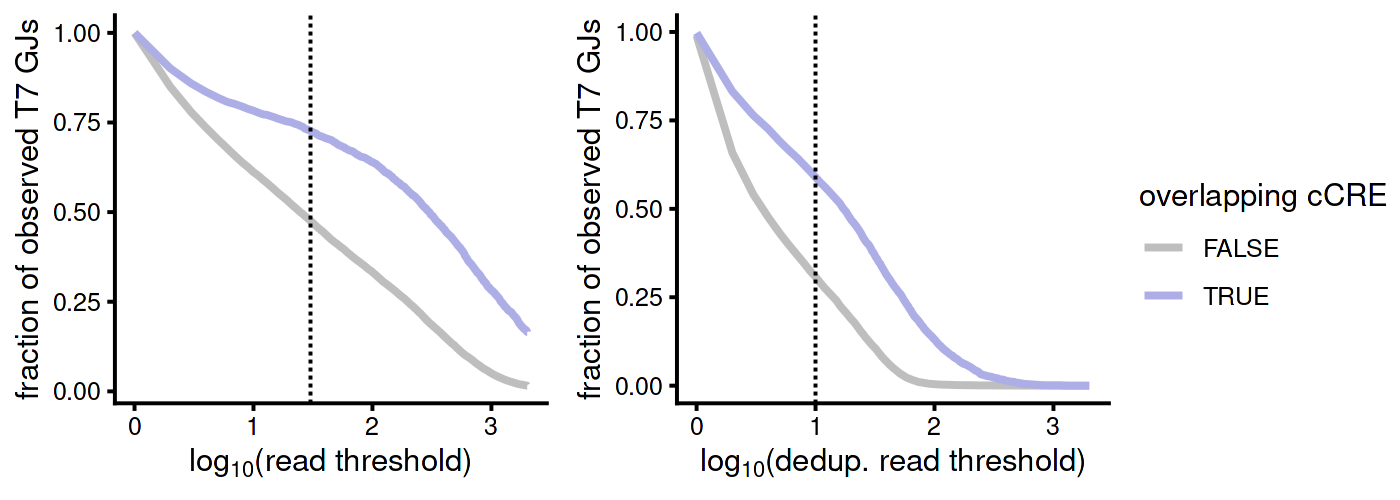

In [35]:
a <- ggplot(cdf_out[cdf_out$metric == "all reads",], 
       aes(x = log10(threshold), 
           y = frac,     
           color = targeting)) +
  geom_line(size = 1) +
  theme_classic() +

  scale_color_manual(values = c("grey", "#aeaee6"))  +
  labs(x = bquote(log[10]*.("(read threshold)")), 
       y = "fraction of observed T7 GJs",
       color = "overlapping cCRE") + geom_vline(xintercept=log10(30),linetype="dashed")

b <- ggplot(cdf_out[cdf_out$metric == "dedup. reads",], 
       aes(x = log10(threshold), 
           y = frac,     
           color = targeting)) +
  geom_line(size = 1) +
  theme_classic() +

  scale_color_manual(values = c("grey", "#aeaee6"))  +
  labs(x = bquote(log[10]*.("(dedup. read threshold)")), 
       y = "fraction of observed T7 GJs",
       color = "overlapping cCRE")+ geom_vline(xintercept=log10(10),linetype="dashed")

options(repr.plot.width = 7, repr.plot.height = 2.5, repr.plot.res = 200)
ggarrange(a,b,ncol=2,nrow=1,common.legend=TRUE,legend="right")

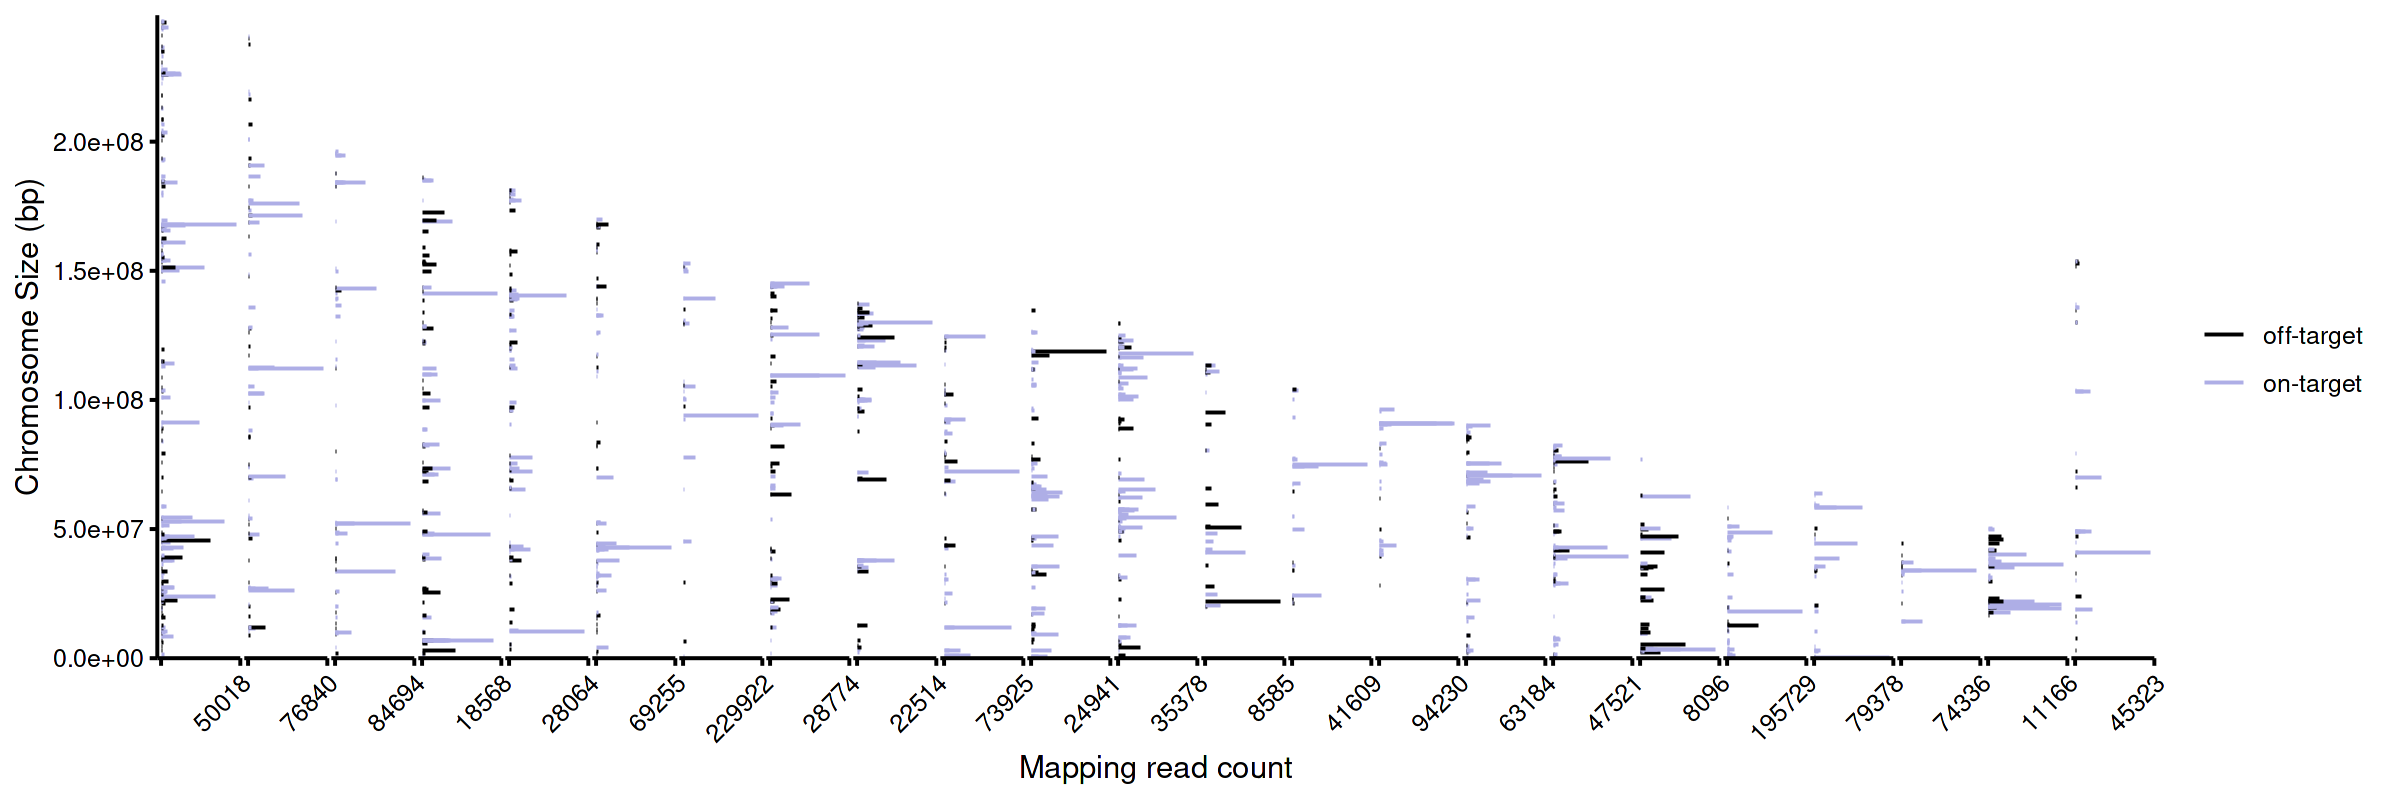

In [36]:
# Rebuild processed objects
r1_t7_processed <- process_sample(r1_t7, CREs_gr, filter = FALSE)
r2_t7_processed <- process_sample(r2_t7, CREs_gr, filter = FALSE)
r3_t7_processed <- process_sample(r3_t7, CREs_gr, filter = FALSE)

r1_t7_processed$replicate <- "r1"
r2_t7_processed$replicate <- "r2"
r3_t7_processed$replicate <- "r3"

r.all <- rbind(r1_t7_processed,
               r2_t7_processed,
               r3_t7_processed)

# Replicate support per junction
rep_support <- aggregate(replicate ~ location + overlapping_CRE,
                         data = r.all[, c("location", "overlapping_CRE", "replicate")],
                         FUN = function(x) length(unique(x)))
colnames(rep_support)[colnames(rep_support) == "replicate"] <- "n_reps"

# Read support summed across replicates
read_support <- aggregate(cbind(n_umis, n_reads) ~ overlapping_CRE + location,
                          data = r.all[, c("n_reads", "n_umis", "overlapping_CRE", "location")],
                          FUN = sum)

# Junctions supported in >=2 replicates
reps_on  <- rep_support[rep_support$n_reps >= 2 & rep_support$overlapping_CRE != "", ]$location
reps_off <- rep_support[rep_support$n_reps >= 2 & rep_support$overlapping_CRE == "", ]$location

# Junctions with >=100 reads across all replicates
reads_on  <- read_support[read_support$n_reads >= 100 & read_support$overlapping_CRE != "", ]$location
reads_off <- read_support[read_support$n_reads >= 100 & read_support$overlapping_CRE == "", ]$location

# Final filtered sets
both_on  <- intersect(reps_on, reads_on)
both_off <- intersect(reps_off, reads_off)

# Build plot dataframe
plot_df <- read_support[read_support$location %in% c(both_on, both_off), ]
plot_df$targeting <- ifelse(plot_df$location %in% both_on, "on-target", "off-target")

# Chromosome sizes
chr.sizes <- read.csv("../t7_mapping/v1_18K_K562/hg38.chrom.standard.sizes",
                      header = FALSE, sep = "\t")
colnames(chr.sizes) <- c("chr", "size")
chr.sizes <- chr.sizes[chr.sizes$chr != "chrY", ]

# Use genomic junction location for chromosome and position
plot_df$chr <- sub("-.*", "", plot_df$location)
plot_df$pos <- as.numeric(sub("^[^-]+-", "", plot_df$location))

chrom_order <- c(paste0("chr", 1:22), "chrX")
chrom_order <- intersect(chrom_order, unique(chr.sizes$chr))
plot_df$chr     <- factor(plot_df$chr, levels = chrom_order)
chr.sizes$chr   <- factor(chr.sizes$chr, levels = chrom_order)

# Same y-axis limit as before
max_size <- max(chr.sizes$size)

# Identical horizontal plot structure, just colored by targeting
suppfig_3d <- ggplot(plot_df, aes(y = pos, xmin = 0, xmax = n_reads, color = targeting)) +
  geom_linerange(orientation = "y") +
  facet_wrap(~ chr, nrow = 1, strip.position = "top", scales = "free_x") +
  scale_y_continuous(
    limits = c(0, max_size),
    expand = expansion(add = c(0, 0)),
    name = "Chromosome Size (bp)"
  ) +
  scale_x_continuous(
    breaks = function(lims) c(0, lims[2]),
    labels = function(x) ifelse(x == 0, "", format(x, scientific = FALSE, digits = 2, trim = TRUE))
  ) +
  scale_color_manual(values = c("on-target" = "#aeaee6", "off-target" = "black")) +
  labs(x = "Mapping read count", color = "") +
  theme_classic() +
  theme(
    strip.text = element_blank(),
    strip.background = element_blank(),
    axis.text.x = element_text(angle = 45, hjust = 1),
    axis.line = element_blank(),
    axis.line.x.bottom = element_line(color = "black"),
    axis.line.y.left   = element_line(color = "black"),
    panel.grid = element_blank(),
    legend.position = "right",
    panel.spacing = unit(0.1, "lines")
  )

options(repr.plot.width = 12, repr.plot.height = 4, repr.plot.res = 200)
suppfig_3d
                         
                                                  
ggsave('../figures/SuppFig3D.pdf', plot = suppfig_3d, 
       width = 160, height = 50, useDingbats = F, units = 'mm', device = 'pdf')

In [37]:
r1_t7_processed <- process_sample(r1_t7, CREs_gr, filter=FALSE)
r2_t7_processed <- process_sample(r2_t7, CREs_gr, filter=FALSE)
r3_t7_processed <- process_sample(r3_t7, CREs_gr, filter=FALSE)

r1_t7_processed$replicate <- "r1"
r2_t7_processed$replicate <- "r2"
r3_t7_processed$replicate <- "r3"

r.all <- rbind(r1_t7_processed,
               r2_t7_processed,
               r3_t7_processed)

rep_support <- aggregate(replicate ~ location + overlapping_CRE,
                         data = r.all[, c("location", "overlapping_CRE", "replicate")],
                         FUN = function(x) length(unique(x)))

colnames(rep_support)[colnames(rep_support) == "replicate"] <- "n_reps"




read_support <- aggregate(cbind(n_umis, n_reads) ~ overlapping_CRE + location,
                          data = r.all[, c("n_reads", "n_umis", "overlapping_CRE", "location")],
                          FUN = sum)

off_loc <- unique(
  rep_support$location[
    rep_support$location %in% read_support$location[
      read_support$overlapping_CRE == "" & read_support$n_reads >= 100
    ] &
    rep_support$overlapping_CRE == "" &
    rep_support$n_reps >= 2
  ]
)

length(off_loc)   # should be 1006

                         
                         
chr.sizes <- read.csv("../t7_mapping/v1_18K_K562/hg38.chrom.standard.sizes", header = FALSE, sep="\t")
colnames(chr.sizes) <- c("chr","size")

chr.sizes <- chr.sizes[chr.sizes$chr != "chrY",]                         


### 2. Convert to GRanges
off_gr <- sites_granges(off_loc)
off_gr <- resize(off_gr, width = 1, fix = "center")


### 3. Make sure chromosomes are standard and present in chr.sizes
off_gr <- keepSeqlevels(off_gr, value = chr.sizes$chr, pruning.mode = "coarse")
CREs_gr_sub <- keepSeqlevels(CREs_gr, value = chr.sizes$chr, pruning.mode = "coarse")

# assign seqlengths from chr.sizes
seqlengths(off_gr) <- chr.sizes$size[match(seqlevels(off_gr), chr.sizes$chr)]
seqlengths(CREs_gr_sub) <- chr.sizes$size[match(seqlevels(CREs_gr_sub), chr.sizes$chr)]


### 4. Distance from observed off-targets to nearest targeted cCRE
obs_hits <- distanceToNearest(off_gr, CREs_gr_sub, ignore.strand = TRUE)
obs_dist <- mcols(obs_hits)$distance

summary(obs_dist)
median(obs_dist)


### 5. Chromosome-matched random controls
make_random_matched_gr <- function(template_gr, chr_sizes_df) {
  chr_tab <- table(as.character(seqnames(template_gr)))
  
  rand_list <- lapply(names(chr_tab), function(chr) {
    n_chr <- chr_tab[[chr]]
    chr_len <- chr_sizes_df$size[match(chr, chr_sizes_df$chr)]
    
    starts <- sample.int(chr_len, size = n_chr, replace = TRUE)
    
    GRanges(
      seqnames = chr,
      ranges = IRanges(start = starts, width = 1)
    )
  })
  
  rand_gr <- do.call("c", rand_list)
  seqlengths(rand_gr) <- chr_sizes_df$size[match(seqlevels(rand_gr), chr_sizes_df$chr)]
  rand_gr
}


### 6. One random control set
set.seed(1)
rand_gr <- make_random_matched_gr(off_gr, chr.sizes)

rand_hits <- distanceToNearest(rand_gr, CREs_gr_sub, ignore.strand = TRUE)
rand_dist <- mcols(rand_hits)$distance

summary(rand_dist)
median(rand_dist)

[1] 1006

    Min.  1st Qu.   Median     Mean  3rd Qu.     Max. 
       5    56168   202722   480032   546654 13397095 

[1] 202722.5

Warning message in .merge_two_Seqinfo_objects(x, y):
“The 2 combined objects have no sequence levels in common. (Use
  suppressWarnings() to suppress this warning.)”
Warning message in .merge_two_Seqinfo_objects(x, y):
“The 2 combined objects have no sequence levels in common. (Use
  suppressWarnings() to suppress this warning.)”
Warning message in .merge_two_Seqinfo_objects(x, y):
“The 2 combined objects have no sequence levels in common. (Use
  suppressWarnings() to suppress this warning.)”
Warning message in .merge_two_Seqinfo_objects(x, y):
“The 2 combined objects have no sequence levels in common. (Use
  suppressWarnings() to suppress this warning.)”
Warning message in .merge_two_Seqinfo_objects(x, y):
“The 2 combined objects have no sequence levels in common. (Use
  suppressWarnings() to suppress this warning.)”
Warning message in .merge_two_Seqinfo_objects(x, y):
“The 2 combined objects have no sequence levels in common. (Use
  suppressWarnings() to suppress this warning.)”
Warn

    Min.  1st Qu.   Median     Mean  3rd Qu.     Max. 
     310   156376   483052  1207951  1241878 18808757 

[1] 483052

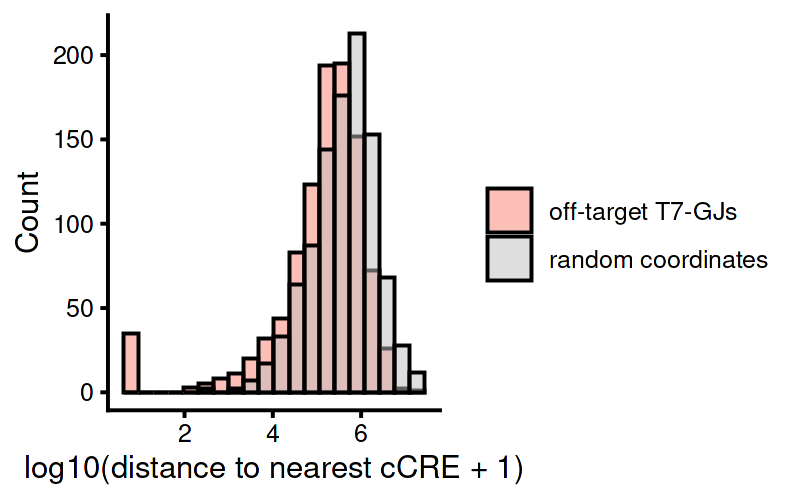

In [38]:
plot_df <- rbind(
  data.frame(distance = obs_dist, type = "off-target T7-GJs"),
  data.frame(distance = rand_dist, type = "random coordinates")
)



plot_df$log10_dist <- log10(plot_df$distance + 1)



dist <- ggplot(plot_df, aes(x = log10_dist, fill = type)) +
  geom_histogram(position = "identity", alpha=.5, bins = 20,color="black") +
  theme_classic() + labs(fill="") +
  scale_fill_manual(values = c("salmon","grey")) +
  xlab("log10(distance to nearest cCRE + 1)") +
  ylab("Count")

options(repr.plot.width = 4, repr.plot.height = 2.5, repr.plot.res = 200)
dist

In [39]:
ggsave('../figures/SuppFig3E.pdf', plot = dist, 
       width = 110, height = 50, useDingbats = F, units = 'mm', device = 'pdf')

Also a version showing the fraction detected in 1, 2 or 3 replicates:

In [40]:
r1_t7_processed <- process_sample(r1_t7, CREs_gr, filter=FALSE)
r2_t7_processed <- process_sample(r2_t7, CREs_gr, filter=FALSE)
r3_t7_processed <- process_sample(r3_t7, CREs_gr, filter=FALSE)

r1_t7_processed$replicate <- "r1"
r2_t7_processed$replicate <- "r2"
r3_t7_processed$replicate <- "r3"

r.all <- rbind(r1_t7_processed,
               r2_t7_processed,
               r3_t7_processed)

rep_support <- aggregate(replicate ~ location + overlapping_CRE,
                         data = r.all[, c("location", "overlapping_CRE", "replicate")],
                         FUN = function(x) length(unique(x)))

colnames(rep_support)[colnames(rep_support) == "replicate"] <- "n_reps"
                         
n_total_on  <- nrow(rep_support[rep_support$overlapping_CRE != "", ])
n_total_off <- nrow(rep_support[rep_support$overlapping_CRE == "", ])
                         
cdf_rep <- data.frame()

for (threshold in 1:3) {
    
    n_GJs <- nrow(rep_support[
      rep_support$n_reps >= threshold & rep_support$overlapping_CRE != "", ])
    cdf_rep <- rbind(cdf_rep,
                     data.frame(threshold = threshold,
                                frac = n_GJs / n_total_on,
                                targeting = "TRUE"))
    
    n_GJs <- nrow(rep_support[
      rep_support$n_reps >= threshold & rep_support$overlapping_CRE == "", ])
    cdf_rep <- rbind(cdf_rep,
                     data.frame(threshold = threshold,
                                frac = n_GJs / n_total_off,
                                targeting = "FALSE"))
}                        

Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on '≥1 rep' in 'mbcsToSbcs': dot substituted for <e2>”
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on '≥1 rep' in 'mbcsToSbcs': dot substituted for <89>”
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on '≥1 rep' in 'mbcsToSbcs': dot substituted for <a5>”
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on '≥2 reps' in 'mbcsToSbcs': dot substituted for <e2>”
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on '≥2 reps' in 'mbcsToSbcs': dot substituted for <89>”
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on '≥2 reps' in 'mbcsToSbcs': dot substituted for <a5>”
Warning message in grid.Call.graphics(C_text, as.graphi

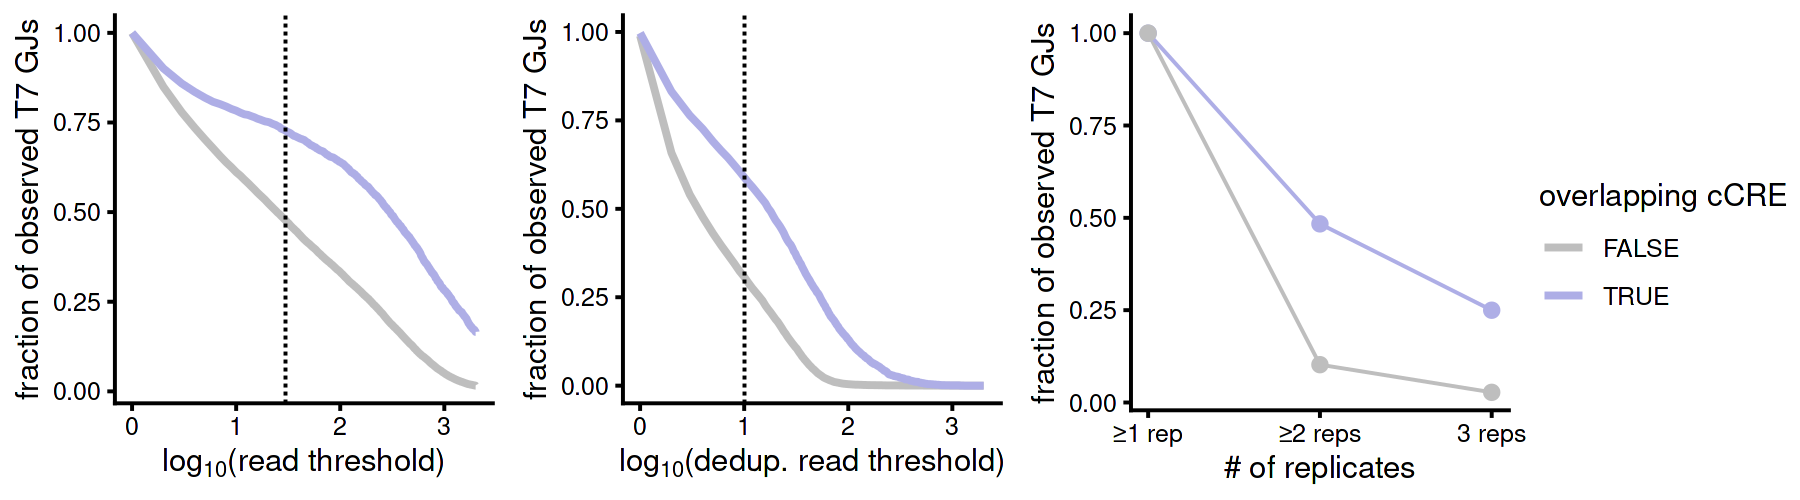

In [41]:
c <- ggplot(cdf_rep, aes(x = threshold, y = frac, color = targeting)) +
  #geom_hline(yintercept=.25,linetype="dashed") +
  geom_line() +
  geom_point(size = 2) +
  scale_x_continuous(breaks = 1:3,
                     labels = c("≥1 rep", "≥2 reps", "3 reps")) +
  theme_classic() +
  scale_color_manual(values = c("grey", "#aeaee6"))  +
  labs(x = "# of replicates", 
       y = "fraction of observed T7 GJs",
       color = "overlapping cCRE")

options(repr.plot.width = 9, repr.plot.height = 2.5, repr.plot.res = 200)
ggarrange(a,b,c,ncol=3,nrow=1,common.legend=TRUE,legend="right")

In [42]:
r1_t7_processed <- process_sample(r1_t7, CREs_gr, filter=FALSE)
r2_t7_processed <- process_sample(r2_t7, CREs_gr, filter=FALSE)
r3_t7_processed <- process_sample(r3_t7, CREs_gr, filter=FALSE)

r1_t7_processed$replicate <- "r1"
r2_t7_processed$replicate <- "r2"
r3_t7_processed$replicate <- "r3"

r.all <- rbind(r1_t7_processed,
               r2_t7_processed,
               r3_t7_processed)

rep_support <- aggregate(replicate ~ location + overlapping_CRE,
                         data = r.all[, c("location", "overlapping_CRE", "replicate")],
                         FUN = function(x) length(unique(x)))
                         
                         
read_support <- aggregate(cbind(n_umis, n_reads) ~ overlapping_CRE+location,
                      data = r.all[,c("n_reads","n_umis","overlapping_CRE","location")],
                      FUN = sum)
  
# getting T7 reads overlapping cCRE supported by at least 2 replicates
reps_on <- rep_support[rep_support$replicate >= 2 & rep_support$overlapping_CRE != "",]$location
# getting T7 reads *not* overlapping cCRE supported by at least 2 replicates
reps_off <- rep_support[rep_support$replicate >= 2 & rep_support$overlapping_CRE == "",]$location
     
# getting T7 reads overlapping cCRE supported by at least 2 replicates
reads_on <- read_support[read_support$n_reads >= 100 & read_support$overlapping_CRE != "",]$location
reads_off <- read_support[read_support$n_reads >= 100 &read_support$overlapping_CRE == "",]$location 

# getting the intersection of T7-GJs overlapping a targeted cCRE that 
# were both detected in at least two replicates and that had at least 
# 100 reads (across all replicates)
both_on <- intersect(reps_on,reads_on)
                         
# getting the intersection of T7-GJs *not* overlapping a targeted cCRE that 
# were both detected in at least two replicates and that had at least 
# 100 reads (across all replicates)
both_off <- intersect(reps_off,reads_off)
                         

# the T7-GJs overlapping a targeted cCRE have a nuance: there should only be at max
# two T7-GJs per cCRE (corresponding to the two designed bottom strand pegRNAs);
# if there are more than two, it is likely alignment jitter. We need to collpase those down:
on_freq <- as.data.frame(table(read_support[read_support$location %in% both_on,]$overlapping_CRE))
on_freq$Freq <- ifelse(on_freq$Freq > 2,2,on_freq$Freq)

# final number of on target T7-GJs detected in at least two replicates
# and with at least 100 reads across both
n_on <- sum(on_freq$Freq)
paste0("# of on-target T7-GJs supported by two replicates and with 100 reads across replicates: ",n_on)
                         
# final number of on target T7-GJs detected in at least two replicates
# and with at least 100 reads across both
n_off <- length(both_off)
paste0("# of off-target T7-GJs supported by two replicates and with 100 reads across replicates: ",n_off)  
                         
n_on <- length(both_on)                      
paste0(
  "At a threshold of 200 reads across all replicates and requiring detection in at least two replicates, ",
  n_on + n_off, " T7-GJs were identified, of which ",
  n_on, " overlapped targeted cCREs and ",
  n_off, " did not."
)

[1] "# of on-target T7-GJs supported by two replicates and with 100 reads across replicates: 1466"

[1] "# of off-target T7-GJs supported by two replicates and with 100 reads across replicates: 1006"

[1] "At a threshold of 200 reads across all replicates and requiring detection in at least two replicates, 2473 T7-GJs were identified, of which 1467 overlapped targeted cCREs and 1006 did not."

In [43]:
table(on_freq$Freq)


  1   2 
930 268 

both

582

neither

1028

both

578

neither

1028

both

566

neither

1070

both

138

neither

710

both

154

neither

709

both

187

neither

753

both

219

neither

1087

both

277

neither

1099

both

259

neither

1158

Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on '≥1 rep' in 'mbcsToSbcs': dot substituted for <e2>”
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on '≥1 rep' in 'mbcsToSbcs': dot substituted for <89>”
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on '≥1 rep' in 'mbcsToSbcs': dot substituted for <a5>”
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on '≥2 reps' in 'mbcsToSbcs': dot substituted for <e2>”
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on '≥2 reps' in 'mbcsToSbcs': dot subs

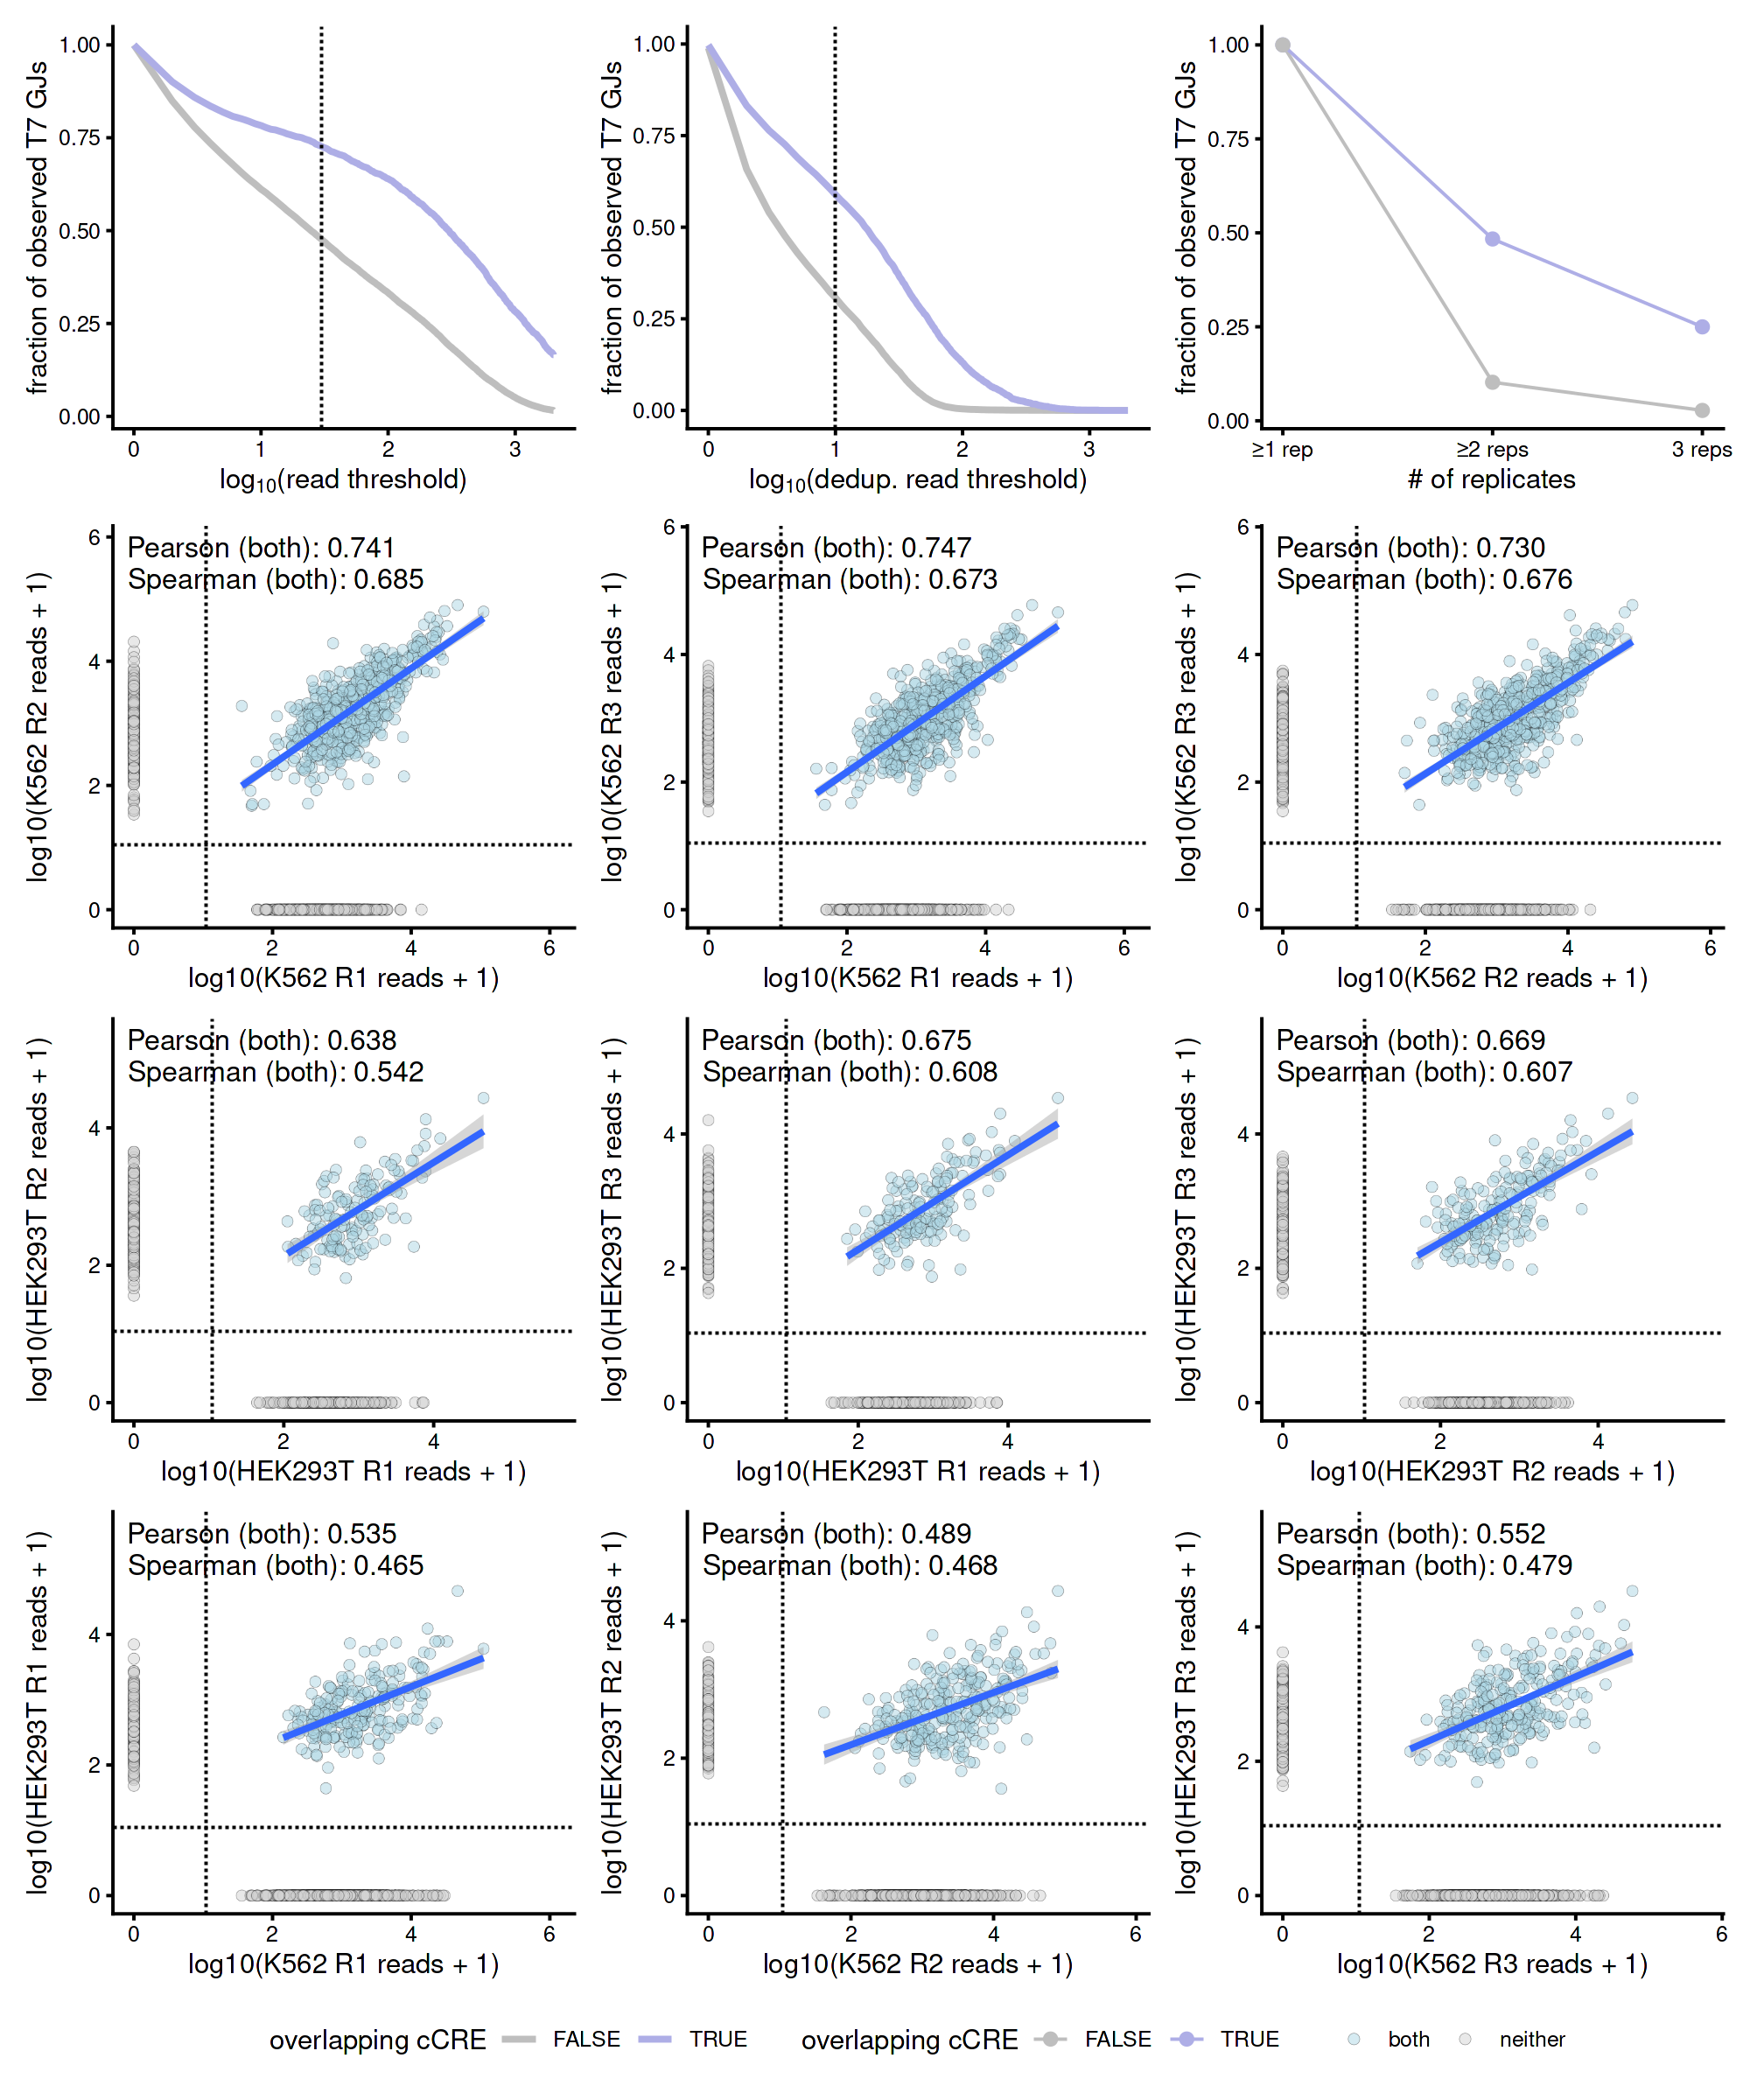

In [44]:
# In the above analyses, I ran process_sample with filter = FALSE
# to keep and analyses off-target T7-GJs, but for the replicated
# comparisons we want to do it with filter = TRUE so we are only looking at 
# on-target effects:
r1_t7_processed <- process_sample(r1_t7, CREs_gr)
r2_t7_processed <- process_sample(r2_t7, CREs_gr)
r3_t7_processed <- process_sample(r3_t7, CREs_gr)

n1_t7_processed <- process_sample(n1_t7, CREs_gr)
n2_t7_processed <- process_sample(n2_t7, CREs_gr)
n3_t7_processed <- process_sample(n3_t7, CREs_gr)


r1_t7_processed_hek <- process_sample(r1_t7_hek, CREs_gr)
r2_t7_processed_hek <- process_sample(r2_t7_hek, CREs_gr)
r3_t7_processed_hek <- process_sample(r3_t7_hek, CREs_gr)

n1_t7_processed_hek <- process_sample(n1_t7_hek, CREs_gr)
n2_t7_processed_hek <- process_sample(n2_t7_hek, CREs_gr)
n3_t7_processed_hek <- process_sample(n3_t7_hek, CREs_gr)




layout <- "
ABC
DEF
GHI
JKL
"

supp_fig3 <- (
  a +
  b +
  c +
  compare_rep(r1_t7_processed,     r2_t7_processed,     "K562 R1",    "K562 R2") +
  compare_rep(r1_t7_processed,     r3_t7_processed,     "K562 R1",    "K562 R3") +
  compare_rep(r2_t7_processed,     r3_t7_processed,     "K562 R2",    "K562 R3") +
  compare_rep(r1_t7_processed_hek, r2_t7_processed_hek, "HEK293T R1", "HEK293T R2") +
  compare_rep(r1_t7_processed_hek, r3_t7_processed_hek, "HEK293T R1", "HEK293T R3") +
  compare_rep(r2_t7_processed_hek, r3_t7_processed_hek, "HEK293T R2", "HEK293T R3") +
  compare_rep(r1_t7_processed,     r1_t7_processed_hek, "K562 R1",    "HEK293T R1") +
  compare_rep(r2_t7_processed,     r2_t7_processed_hek, "K562 R2",    "HEK293T R2") +
  compare_rep(r3_t7_processed,     r3_t7_processed_hek, "K562 R3",    "HEK293T R3")
) +
  plot_layout(design = layout, guides = "collect") &
  theme(legend.position = "bottom")

options(repr.plot.width = 10, repr.plot.height = 12, repr.plot.res = 200)
supp_fig3

In [45]:
ggsave('../figures/SuppFig3.pdf', plot = supp_fig3, 
       width = 205, height = 255, useDingbats = F, units = 'mm', device = 'pdf')

In [46]:
sessionInfo()

R version 4.3.2 (2023-10-31)
Platform: x86_64-pc-linux-gnu (64-bit)
Running under: Ubuntu 22.04.4 LTS

Matrix products: default
BLAS:   /net/gs/vol3/software/modules-sw/R/4.3.2/Linux/Ubuntu22.04/x86_64/lib/R/lib/libRblas.so 
LAPACK: /net/gs/vol3/software/modules-sw/R/4.3.2/Linux/Ubuntu22.04/x86_64/lib/R/lib/libRlapack.so;  LAPACK version 3.11.0

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

time zone: America/Los_Angeles
tzcode source: system (glibc)

attached base packages:
[1] grid      stats4    stats     graphics  grDevices utils     datasets 
[8] methods   base     

other attached packages:
 [1] ggrastr_1.0.2                           
 [2] cowplot_1.2.0                           
 [3] patchwork_1.3.2                         